# Tecnológico de Monterrey

**Maestría en Inteligencia Artificial Aplicada**  
**Proyecto Integrador - Avance 3: Modelo de Referencia (Baseline)**  
**Proyecto:** Multipricing para Cash Management / Global Transaction Banking (GTB)  
**Profesor:** Dr. Horacio Martínez Alfaro  
**Equipo 9 - Cash Optimization**  

| Integrante | Matrícula |
|---|---|
| Oscar Benjamín Zacarías Villegas | A01797160 |
| Mariana Paola De los Cobos Kingston | A01796922 |
| Gerardo Tenorio Castillo | A01139576 |

## Propósito de la entrega

Este avance compara formas sencillas de pronosticar el número de operaciones del siguiente mes. El objetivo es conocer qué tan difícil es superar una regla básica, en qué casos se producen los errores más grandes y cuál será el punto de partida de la siguiente entrega. **No se entrenan modelos avanzados ni se realiza una búsqueda extensa de configuraciones.**

**Ejecución y trazabilidad.** Los resultados se guardan en una carpeta nueva dentro de `artifacts_e3/final/` para cada corrida. Se verifica automáticamente que las cifras de esta entrega sigan coincidiendo con los datos cargados, antes del cierre.

## Alcance, datos y criterios definidos antes del entrenamiento

El resultado a pronosticar es `operaciones_t1`, es decir, las operaciones de cada unidad contractual durante el mes siguiente. La predicción usa solamente información disponible al cierre del mes actual. La unidad de análisis combina grupo, cliente, línea de contrato, convenio, producto, subproducto y moneda. Cuando se necesite una visión corporativa, las predicciones pueden sumarse por grupo y mes.

Se conservan los datos preparados en E2, sin rehacer sus transformaciones: **Dataset A**, con variables interpretables, y **Dataset B**, que incluye una reducción mediante PCA. Train cubre septiembre de 2023 a agosto de 2025; Validation, septiembre de 2025 a febrero de 2026; Test, marzo a julio de 2026. Test permanece reservado y no interviene en las decisiones de este avance.

**Criterio de evaluación, establecido antes de ajustar los modelos:** la métrica principal es el **error absoluto medio (MAE)**, expresado en operaciones. Es fácil de interpretar: cuanto menor sea, menor es el error promedio por observación. Como apoyo se utilizarán RMSE, WAPE y MdAE. La comparación entre modelos se decidirá por MAE; las otras métricas ayudan a entender sus ventajas y limitaciones.

No se completarán operaciones faltantes con ceros ni se inventarán meses sin actividad. Las métricas corresponden a los contratos cuyo resultado del mes siguiente pudo observarse.

### Preparación y comprobación de los datos

Antes de entrenar, se comprueba que las matrices A y B coincidan con sus variables, llaves y resultados de E2. También se verifica el objetivo del mes siguiente contra el archivo original y se revisa la cobertura de cada periodo. Estas tareas aseguran que todos los modelos sean comparados sobre las mismas observaciones.

In [1]:
import gc
import hashlib
import json
import os
import platform
import secrets
import time
import warnings
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy import sparse
from scipy.stats import ks_2samp, skew
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 75)
pd.set_option('display.width', 170)

# Una sola celda configurable. Las variables de entorno tienen prioridad.
CARPETA_PROYECTO = Path(os.getenv('PROYECTO_DIR', '/content/drive/MyDrive/Colab Notebooks/Proyecto Integrador'))
BASE_MULTIPRICING_PATH = os.getenv('BASE_MULTIPRICING_PATH', '')
ARTIFACTS_E2_PATH = os.getenv('ARTIFACTS_E2_PATH', '')
ARTIFACTS_E3_FINAL_PATH = os.getenv('ARTIFACTS_E3_FINAL_PATH', '')
PSEUDONYM_KEY_EXTERNALLY_PROVIDED = bool(os.getenv('E3_PSEUDONYM_KEY', ''))
PSEUDONYM_KEY = os.getenv('E3_PSEUDONYM_KEY', '') or secrets.token_hex(32)
VERIFICAR_CIFRAS_REFERENCIA = os.getenv('E3_VERIFY_REFERENCE', '1').strip() != '0'  # Desactivar solo en pruebas sintéticas

METRICA_PRIMARIA = 'MAE'
METRICAS_SECUNDARIAS = ('RMSE','WAPE','MdAE')
UMBRAL_LIFT_B0 = 10.0
UMBRAL_LIFT_B1 = 5.0
ALPHA_RIDGE = 1.0
RIDGE_ORIGINAL = {'alpha':ALPHA_RIDGE, 'solver':'lsqr', 'tol':1e-3, 'max_iter':600}
CV_RIDGE = {'alpha':ALPHA_RIDGE, 'solver':'lsqr', 'tol':1e-5, 'max_iter':900}


def localizar_e2():
    paths = ([Path(ARTIFACTS_E2_PATH).expanduser()] if ARTIFACTS_E2_PATH else [])
    paths += [CARPETA_PROYECTO/'artifacts_e2', Path('/content/artifacts_e2'), Path.cwd()/'artifacts_e2']
    for path in paths:
        if (path/'X_train_A.npz').is_file(): return path.resolve()
    try:
        from google.colab import drive
        if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
    except ImportError:
        pass
    for path in paths:
        if (path/'X_train_A.npz').is_file(): return path.resolve()
    raise FileNotFoundError('No se localizo artifacts_e2. Establezca ARTIFACTS_E2_PATH o monte Drive.')

ART_E2 = localizar_e2()
ART_E3_ROOT = (Path(ARTIFACTS_E3_FINAL_PATH).expanduser() if ARTIFACTS_E3_FINAL_PATH
               else ART_E2.parent/'artifacts_e3'/'final')
if ART_E3_ROOT.resolve() == ART_E2.resolve() or ART_E2.resolve() in ART_E3_ROOT.resolve().parents:
    raise ValueError('La carpeta de salida no puede coincidir con E2 ni estar dentro de ella.')
# Se crea una carpeta NUEVA para cada corrida, incluso si se especifica una ruta manual.
RUN_ID = os.getenv('E3_RUN_ID', '').strip() or (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+secrets.token_hex(4))
if not __import__('re').fullmatch(r'[A-Za-z0-9_-]{1,72}', RUN_ID):
    raise ValueError('E3_RUN_ID solo admite letras, números, guion y guion bajo.')
ART_E3 = ART_E3_ROOT / ('corrida_'+RUN_ID)
ART_E3.mkdir(parents=True, exist_ok=False)
print('Fuente E2:', ART_E2)
print('Salida E3 (corrida aislada):', ART_E3)
print('Pseudónimos comparables entre ejecuciones:', PSEUDONYM_KEY_EXTERNALLY_PROVIDED)
if not PSEUDONYM_KEY_EXTERNALLY_PROVIDED:
    print('AVISO: para cotejar hashes entre corridas, defina una misma E3_PSEUDONYM_KEY privada fuera del notebook.')
print('Protocolo previo al ajuste:', METRICA_PRIMARIA, METRICAS_SECUNDARIAS, UMBRAL_LIFT_B0, UMBRAL_LIFT_B1, RIDGE_ORIGINAL)


def pred_no_negativa(v):
    z = np.asarray(v, dtype=np.float64).reshape(-1)
    if not np.isfinite(z).all(): raise ValueError('Prediccion no finita; se detiene la ejecucion.')
    return np.maximum(0, z)


def lift_mae(reference_mae, candidate_mae):
    return 100*(1-candidate_mae/reference_mae) if reference_mae>0 else np.nan


def seudonimo(x, tipo):
    if pd.isna(x): return 'NO_DISPONIBLE'
    return hashlib.sha256((str(tipo)+'|'+str(x)+'|'+PSEUDONYM_KEY).encode()).hexdigest()[:20]


def mae_grupo_mes(yt, yp, k):
    z = pd.DataFrame({'grupo':k['id_grupo'].to_numpy(),
                      'mes_objetivo':(k['fecha_corte']+pd.offsets.MonthEnd(1)).to_numpy(),
                      'real':np.asarray(yt), 'pred':np.asarray(yp)})
    agg = z.groupby(['grupo','mes_objetivo'], dropna=False)[['real','pred']].sum()
    return float(np.abs(agg['real']-agg['pred']).mean())


def metricas_regresion(yt, yp, k):
    yt = np.asarray(yt, dtype=float)
    yp = pred_no_negativa(yp)
    assert len(yt)==len(yp)==len(k)
    ea = np.abs(yt-yp)
    return {'MAE':float(ea.mean()),'RMSE':float(np.sqrt(np.mean((yt-yp)**2))),
            'WAPE':float(100*ea.sum()/yt.sum()) if yt.sum()>0 else np.nan,
            'MdAE':float(np.median(ea)), 'MAE_grupo_mes':mae_grupo_mes(yt,yp,k),
            'sesgo_pred_menos_real':float(np.mean(yp-yt))}


def guardar_csv(frame, nombre):
    frame.to_csv(ART_E3/nombre, index=False)

Mounted at /content/drive
Fuente E2: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e2
Salida E3 (corrida aislada): /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e3/final/corrida_20261021T024601Z_9097ef26
Pseudónimos comparables entre ejecuciones: False
AVISO: para cotejar hashes entre corridas, defina una misma E3_PSEUDONYM_KEY privada fuera del notebook.
Protocolo previo al ajuste: MAE ('RMSE', 'WAPE', 'MdAE') 10.0 5.0 {'alpha': 1.0, 'solver': 'lsqr', 'tol': 0.001, 'max_iter': 600}


In [2]:
NECESARIOS = [*(f'X_{p}_{rama}.npz' for p in ('train','validation','test') for rama in ('A','B')),
              *(f'y_{p}.csv' for p in ('train','validation','test')),
              *(f'keys_{p}.csv' for p in ('train','validation','test')),
              'preprocessor_A.joblib','preprocessor_B.joblib',
              'feature_names_A.csv','feature_names_B.csv',
              'feature_manifest_completo.csv','feature_config.json']
faltantes = [nombre for nombre in NECESARIOS if not (ART_E2/nombre).is_file()]
if faltantes: raise FileNotFoundError('Artefactos E2 faltantes: '+', '.join(faltantes))

SPLITS = ('train','validation')
X = {rama:{p:sparse.load_npz(ART_E2/f'X_{p}_{rama}.npz').tocsr() for p in SPLITS} for rama in ('A','B')}
y = {p:pd.read_csv(ART_E2/f'y_{p}.csv')['operaciones_t1'].to_numpy(dtype=float) for p in SPLITS}
keys = {p:pd.read_csv(ART_E2/f'keys_{p}.csv') for p in SPLITS}
feature_names = {rama:pd.read_csv(ART_E2/f'feature_names_{rama}.csv')['feature'].astype(str).to_numpy()
                 for rama in ('A','B')}
manifest = pd.read_csv(ART_E2/'feature_manifest_completo.csv')
config_e2 = json.loads((ART_E2/'feature_config.json').read_text(encoding='utf-8'))

for p in SPLITS:
    keys[p]['fecha_corte'] = pd.to_datetime(keys[p]['fecha_corte'],errors='raise').dt.normalize()
    assert len(y[p])>0 and len(keys[p])==len(y[p])
    assert np.isfinite(y[p]).all() and (y[p]>=0).all()
    assert not keys[p].duplicated().any(), 'Llaves duplicadas: '+p
    for rama in ('A','B'):
        assert X[rama][p].shape==(len(y[p]),len(feature_names[rama])), (rama,p,X[rama][p].shape)
        assert np.isfinite(X[rama][p].data).all(), (rama,p)
    assert keys[p].columns.tolist()==keys['train'].columns.tolist()

assert keys['train']['fecha_corte'].between('2023-09-01','2025-08-31').all()
assert keys['validation']['fecha_corte'].between('2025-09-01','2026-02-28').all()
assert keys['train']['fecha_corte'].max()<keys['validation']['fecha_corte'].min()
assert len(set(feature_names['A']))==len(feature_names['A'])
assert len(set(feature_names['B']))==len(feature_names['B'])
assert {'feature_final','feature_origen','familia','dataset_A','dataset_B'}.issubset(manifest.columns)
for rama in ('A','B'):
    sub = manifest.loc[manifest[f'dataset_{rama}'].astype(str).str.lower().eq('true'),'feature_final'].astype(str)
    if not set(feature_names[rama]).issubset(set(sub)):
        raise ValueError('La representacion '+rama+' no coincide con su manifiesto E2.')
    assert not any(('operaciones_t1' in v or 'ratio_retencion_ops' in v or 'caida_ops_50pct' in v)
                   for v in feature_names[rama]), 'Posible target leakage en E2.'

# Test: ninguna matriz ni y_test se carga o consulta.
test_fechas = pd.read_csv(ART_E2/'keys_test.csv', usecols=['fecha_corte'])['fecha_corte']
ntest = len(test_fechas)
assert pd.to_datetime(test_fechas).between('2026-03-01','2026-07-31').all()
resumen_split = pd.DataFrame([
    {'split':p,'n':len(y[p]),'features_A':X['A'][p].shape[1],'features_B':X['B'][p].shape[1]} for p in SPLITS
]+[{'split':'test_reservado','n':ntest,'features_A':len(feature_names['A']), 'features_B':len(feature_names['B'])}])
resumen_split['pct_total'] = 100*resumen_split['n']/resumen_split['n'].sum()
display(resumen_split.round(2))
refs = {'train':498093,'validation':99012,'test_reservado':97279}
if any(int(row.n)!=refs[row.split] for row in resumen_split.itertuples(index=False)):
    print('AVISO: tamanos E2 diferentes a las referencias historicas; verificar la version antes de comparar.')
else: print('Conteos de particiones conciliados con E2 historico.')

,split,n,features_A,features_B,pct_total
0,train,498093,387,362,71.73
1,validation,99012,387,362,14.26
2,test_reservado,97279,387,362,14.01


Conteos de particiones conciliados con E2 historico.


In [3]:
COLUMNAS_ORIGINALES = ['id_grupo','id_cliente','negocio','línea_contrato','producto',
                      'subproducto','convenio','moneda','numero_operaciones','tarifa_vigente',
                      'tarifa_anaquel','ingreso_bruto','seniority','fecha_corte','industria']
LLAVE_UNIDAD = ['id_grupo','id_cliente','línea_contrato','convenio','producto','subproducto','moneda']
LLAVE_OBS = ['fecha_corte']+LLAVE_UNIDAD
candidatos = ([Path(BASE_MULTIPRICING_PATH).expanduser()] if BASE_MULTIPRICING_PATH else [])
candidatos += [ART_E2.parent/'Base_multipricing.csv',CARPETA_PROYECTO/'Base_multipricing.csv',
               Path('/content/Base_multipricing.csv'),Path.cwd()/'Base_multipricing.csv']
RUTA_BASE = next((q for q in candidatos if q.is_file()),None)
if RUTA_BASE is None: raise FileNotFoundError('No se encontro Base_multipricing.csv. Configure BASE_MULTIPRICING_PATH.')
raw = pd.read_csv(RUTA_BASE,names=COLUMNAS_ORIGINALES,header=None,index_col=False,low_memory=False)
raw['fecha_corte'] = pd.to_datetime(raw['fecha_corte'],errors='coerce').dt.normalize()
raw['seniority'] = pd.to_datetime(raw['seniority'],errors='coerce').dt.normalize()
for c in ['numero_operaciones','tarifa_vigente','tarifa_anaquel','ingreso_bruto']:
    raw[c] = pd.to_numeric(raw[c],errors='coerce')

fuente_mensual = (raw.groupby('fecha_corte',dropna=False,observed=True)
    .agg(filas_fuente=('id_grupo','size'),grupos_fuente=('id_grupo','nunique'),
         volumen_fuente=('numero_operaciones','sum')).reset_index())
cuantos = raw.groupby(LLAVE_OBS,dropna=False,observed=True)['numero_operaciones'].transform('size')
fuente_anomalias = pd.DataFrame([{'n_original':len(raw),'n_no_univocas':int(cuantos.gt(1).sum()),
    'n_ausentes_ops':int(raw['numero_operaciones'].isna().sum())}])
obs = raw.loc[cuantos.eq(1),LLAVE_OBS+['numero_operaciones','tarifa_vigente','tarifa_anaquel',
                                     'ingreso_bruto','seniority','industria']].copy()
del raw,cuantos
gc.collect()
obs.sort_values(LLAVE_UNIDAD+['fecha_corte'],inplace=True)
unit = obs.groupby(LLAVE_UNIDAD,dropna=False,observed=True,sort=False)
mes = obs['fecha_corte'].dt.year*12+obs['fecha_corte'].dt.month
prox_mes = unit['fecha_corte'].shift(-1)
prox_mes_idx = prox_mes.dt.year*12+prox_mes.dt.month
prox_ops = unit['numero_operaciones'].shift(-1)
obs['y_reconstruido'] = prox_ops.where((prox_mes_idx-mes).eq(1))

prev_mes = unit['fecha_corte'].shift(1)
prev_idx = prev_mes.dt.year*12+prev_mes.dt.month
continua = (mes-prev_idx).eq(1)
prev_tar = unit['tarifa_vigente'].shift(1)
cambio_pct = (obs['tarifa_vigente']/prev_tar-1)*100
obs['repricing_flag_t'] = (continua & prev_tar.gt(0) & obs['tarifa_vigente'].gt(0) &
                            cambio_pct.abs().ge(5)).astype('int8')
obs['historia_1m_disponible'] = continua.astype('int8')
obs['estado_continuidad'] = np.select([continua,unit.cumcount().gt(0)],
    ['Continua','Reaparece tras hueco'],default='Sin historia anterior')
grupo_mes = obs.groupby(['fecha_corte','id_grupo'],dropna=False,observed=True,sort=False)
obs['grupo_ops_total_t'] = grupo_mes['numero_operaciones'].transform('sum')
obs['grupo_n_productos'] = grupo_mes['producto'].transform('nunique')
obs['grupo_n_subproductos'] = grupo_mes['subproducto'].transform('nunique')
obs['share_ops_grupo'] = obs['numero_operaciones']/obs['grupo_ops_total_t'].where(obs['grupo_ops_total_t'].gt(0))

raw_alineado={}
for p in SPLITS:
    k=keys[p].copy()
    k['_orden_e2'] = np.arange(len(k),dtype=np.int64)
    j = k.merge(obs,on=LLAVE_OBS,how='left',validate='one_to_one',indicator=True,sort=False)
    if len(j)!=len(k) or not j['_merge'].eq('both').all():
        raise RuntimeError('Desalineacion de llaves E2 vs CSV original: '+p)
    j = j.sort_values('_orden_e2').reset_index(drop=True)
    if not np.isfinite(j['numero_operaciones']).all(): raise ValueError('ops_t invalida: '+p)
    if not np.allclose(j['y_reconstruido'].to_numpy(float),y[p],rtol=1e-10,atol=1e-6):
        raise RuntimeError('Target E2 no coincide con t+1 calendarizado: '+p)
    raw_alineado[p] = j
ops={p:raw_alineado[p]['numero_operaciones'].to_numpy(float) for p in SPLITS}
assert all((ops[p]>=0).all() for p in SPLITS)
assert all(len(ops[p])==len(y[p]) for p in SPLITS)
print('Verificacion de ops_t y operaciones_t1 exacta en Train y Validation.')
print('Fuente:',RUTA_BASE)
display(fuente_anomalias)

# Un solo diagnostico mensual: cobertura fuente y cobertura evaluable.
cob_eval = pd.concat([keys[p].assign(split=p) for p in SPLITS],ignore_index=True)
cob_eval = cob_eval.groupby('fecha_corte',observed=True).agg(
    n_evaluable=('id_grupo','size'),grupos_evaluables=('id_grupo','nunique')).reset_index()
cobertura_mensual = fuente_mensual.merge(cob_eval,on='fecha_corte',how='left')
cobertura_mensual['pct_filas_evaluables'] = 100*cobertura_mensual['n_evaluable']/cobertura_mensual['filas_fuente']

del obs,unit,grupo_mes,prox_mes,prox_ops,prev_mes,prev_tar
# Las llaves y targets Test no se reconstruyen ni se usan.
gc.collect()

Verificacion de ops_t y operaciones_t1 exacta en Train y Validation.
Fuente: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/Base_multipricing.csv


,n_original,n_no_univocas,n_ausentes_ops
0,870591,27677,0


63

## E3-Q1 - Modelos de referencia

**Qué queremos comprobar.** ¿Una regla tan sencilla como repetir las operaciones del mes actual puede superar a una regresión que utiliza las variables de E2? Este es el punto de partida para conocer el valor que aportan los modelos.

Comparamos cuatro alternativas con el mismo Train y Validation: **B0**, que pronostica siempre la mediana de Train; **B1**, que repite las operaciones del mes actual; **B2**, una regresión Ridge con Dataset A; y **B3**, Ridge con Dataset B y PCA. Los dos Ridge utilizan la misma regularización fijada previamente y no pasan por una búsqueda de hiperparámetros. Después se comprueba si las soluciones de Ridge son numéricamente estables.

,split,modelo,MAE,RMSE,WAPE,MdAE,MAE_grupo_mes,sesgo_pred_menos_real,fit_segundos,lift_vs_B0_%,lift_vs_B1_%
1,train,B1_persistencia,327.141,12907.697,19.787,4.000,7580.113,-8.601,0.000,80.127,0.000
2,train,B2_Ridge_A,336.336,9733.617,20.343,13.388,7594.604,1.123,3.444,79.568,-2.811
0,train,B0_constante,1646.139,28415.244,99.567,21.000,52971.627,-1631.291,0.000,0.000,-403.190
3,train,B3_Ridge_B,2385.952,21997.825,144.315,375.634,53972.897,1214.926,6.863,-44.942,-629.335
5,validation,B1_persistencia,399.785,13501.972,25.718,4.000,8214.252,-37.149,0.000,74.164,0.000
6,validation,B2_Ridge_A,427.669,13584.527,27.511,15.123,8508.350,-70.954,3.444,72.362,-6.975
4,validation,B0_constante,1547.371,26728.726,99.540,21.000,41603.668,-1532.523,0.000,0.000,-287.051
7,validation,B3_Ridge_B,2671.717,24310.360,171.867,461.287,55166.902,1478.861,6.863,-72.662,-568.289


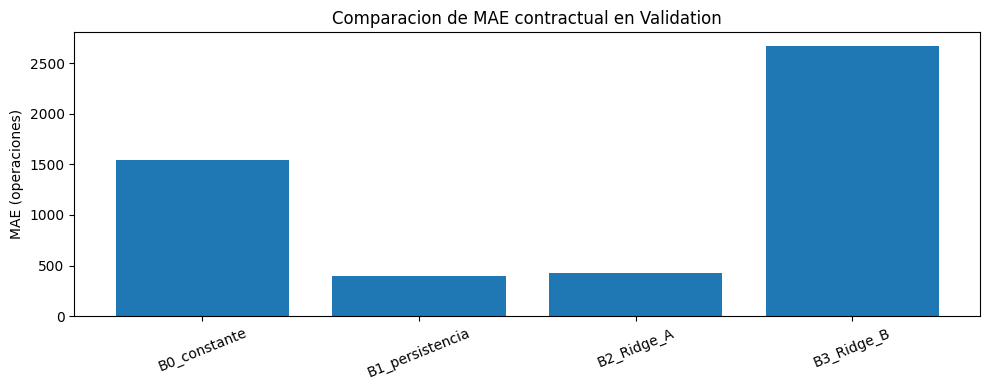

In [4]:
MODELOS = ('B0_constante','B1_persistencia','B2_Ridge_A','B3_Ridge_B')
mediana_train=float(np.median(y['train']))
modelos_ridge={}
predicciones={p:{} for p in SPLITS}
fit_segundos=dict.fromkeys(MODELOS,0.0)
for p in SPLITS:
    predicciones[p]['B0_constante']=np.full(len(y[p]),mediana_train,dtype=float)
    predicciones[p]['B1_persistencia']=ops[p].copy()
for rama,nombre in [('A','B2_Ridge_A'),('B','B3_Ridge_B')]:
    model=Ridge(**RIDGE_ORIGINAL)
    inicio=time.perf_counter()
    model.fit(X[rama]['train'],y['train'])
    fit_segundos[nombre]=time.perf_counter()-inicio
    modelos_ridge[rama]=model
    for p in SPLITS: predicciones[p][nombre]=pred_no_negativa(model.predict(X[rama][p]))

metricas=pd.DataFrame([{'split':p,'modelo':nombre,**metricas_regresion(
    y[p],predicciones[p][nombre],keys[p]),'fit_segundos':fit_segundos[nombre]}
    for p in SPLITS for nombre in MODELOS])
mae_val=metricas.loc[metricas['split']=='validation'].set_index('modelo')['MAE']
mae_const=float(mae_val['B0_constante'])
mae_persistencia=float(mae_val['B1_persistencia'])
mejor_referencia=mae_val.idxmin()
mejor_aprendido=min(('B2_Ridge_A','B3_Ridge_B'),key=lambda m:float(mae_val[m]))
comparacion=metricas.copy()
for p in SPLITS:
    para=comparacion['split'].eq(p)
    sub=comparacion.loc[para].set_index('modelo')
    comparacion.loc[para,'lift_vs_B0_%']=[lift_mae(sub.loc['B0_constante','MAE'],v) for v in sub['MAE']]
    comparacion.loc[para,'lift_vs_B1_%']=[lift_mae(sub.loc['B1_persistencia','MAE'],v) for v in sub['MAE']]
display(comparacion.sort_values(['split','MAE']).round(3))

fig,ax=plt.subplots(figsize=(10,4))
t=comparacion.loc[comparacion['split'].eq('validation')].set_index('modelo').reindex(MODELOS)
ax.bar(t.index,t['MAE']);ax.set(title='Comparacion de MAE contractual en Validation',ylabel='MAE (operaciones)')
ax.tick_params(axis='x',rotation=22);plt.tight_layout();plt.show()

### Comprobación de estabilidad numérica de Ridge

Antes de interpretar una regresión, comprobamos si el cálculo encuentra una solución suficientemente estable. Comparamos la configuración original con dos formas más precisas de resolver el mismo problema, manteniendo fija la regularización (α = 1). **No son modelos nuevos ni candidatos adicionales**: esta revisión únicamente comprueba la confiabilidad numérica del baseline lineal.

Además del MAE, examinamos el valor del objetivo que Ridge intenta minimizar durante Train y cuánto cambian sus coeficientes. Un MAE favorable no demuestra por sí solo que el algoritmo haya terminado de resolver correctamente ese objetivo.

In [5]:
def objetivo_ridge(modelo):
    r=y['train']-modelo.predict(X['A']['train'])
    return float(np.dot(r,r)+ALPHA_RIDGE*np.dot(modelo.coef_,modelo.coef_))

baseline_obj=objetivo_ridge(modelos_ridge['A'])
auditoria_ridge=[{'solver':'lsqr','tol':RIDGE_ORIGINAL['tol'],
  'max_iter':RIDGE_ORIGINAL['max_iter'],'estado':'historico',
  'objetivo_train':baseline_obj,'norma_coeficientes':float(np.linalg.norm(modelos_ridge['A'].coef_)),
  'mae_validation':float(mae_val['B2_Ridge_A']), 'diferencia_rel_predicciones':0.0,
  'fit_segundos':fit_segundos['B2_Ridge_A']}]
modelos_auditados={}
for cfg in ({'solver':'lsqr','tol':1e-7,'max_iter':1800},
            {'solver':'sparse_cg','tol':1e-6,'max_iter':1200}):
    tic=time.perf_counter()
    try:
        est=Ridge(alpha=ALPHA_RIDGE,**cfg)
        est.fit(X['A']['train'],y['train'])
        yp=pred_no_negativa(est.predict(X['A']['validation']))
        d=np.linalg.norm(yp-predicciones['validation']['B2_Ridge_A']) / max(
            1.0,np.linalg.norm(predicciones['validation']['B2_Ridge_A']))
        auditoria_ridge.append({'solver':cfg['solver'],'tol':cfg['tol'],'max_iter':cfg['max_iter'],
            'estado':'estimado','objetivo_train':objetivo_ridge(est),
            'norma_coeficientes':float(np.linalg.norm(est.coef_)),
            'mae_validation':float(mean_absolute_error(y['validation'],yp)),
            'diferencia_rel_predicciones':float(d),'fit_segundos':time.perf_counter()-tic})
        modelos_auditados[cfg['solver']]=est
    except (ValueError,TypeError,RuntimeError,MemoryError) as exc:
        auditoria_ridge.append({'solver':cfg['solver'],'tol':cfg['tol'],
            'max_iter':cfg['max_iter'],'estado':'no_disponible: '+type(exc).__name__,
            'objetivo_train':np.nan,'norma_coeficientes':np.nan,
            'mae_validation':np.nan,'diferencia_rel_predicciones':np.nan,
            'fit_segundos':time.perf_counter()-tic})
num_ridge=pd.DataFrame(auditoria_ridge)
num_ridge['mejora_objetivo_pct']=100*(baseline_obj-num_ridge['objetivo_train'])/max(abs(baseline_obj),1e-12)
display(num_ridge.round(5))

# No se declara convergencia por un MAE favorable. Usar coeficientes de la
# solucion de menor objetivo conocido solo para diagnosticos correlacionales.
validas=num_ridge.loc[num_ridge.estado.eq('estimado')].sort_values('objetivo_train')
if len(validas) and validas.iloc[0]['objetivo_train'] < baseline_obj:
    origen_coef=str(validas.iloc[0]['solver'])
    ridge_importancia=modelos_auditados[origen_coef]
else:
    origen_coef='lsqr_original_sin_verificacion_externa'
    ridge_importancia=modelos_ridge['A']
num_ridge['referencia_importancia']=np.where(num_ridge['solver'].eq(origen_coef),'elegida_por_objetivo_train','')
print('Solucion utilizada para el diagnostico de coeficientes:',origen_coef)

,solver,tol,max_iter,estado,objetivo_train,norma_coeficientes,mae_validation,diferencia_rel_predicciones,fit_segundos,mejora_objetivo_pct
0,lsqr,0.001,600,historico,4.719102e+13,248.15136,427.66864,0.00000,3.44431,0.00000
1,lsqr,0.000,1800,estimado,4.668933e+13,61702.41629,821.12380,0.05782,109.67228,1.06310
2,sparse_cg,0.000,1200,estimado,4.666568e+13,65880.55959,771.06953,0.05555,171.06080,1.11322


Solucion utilizada para el diagnostico de coeficientes: sparse_cg


### Conclusión de Q1

**Persistencia fue la mejor referencia.** En Validation obtuvo un **MAE de 399.78 operaciones**, frente a **501.84 de Ridge A**, **1,480.21 de Ridge B** y **1,547.37 del predictor constante**. En este conjunto, repetir las operaciones del mes actual funciona mejor, en promedio, que las dos regresiones probadas.

**La revisión numérica encontró una limitación importante de Ridge A.** Al exigir una solución más precisa, disminuyó el objetivo matemático calculado en Train, pero los coeficientes cambiaron considerablemente y el MAE de Validation empeoró. Es posible que la detención temprana de la configuración original esté actuando como una forma adicional de regularización. Por eso **B2 se conserva como comparación histórica reproducible, no como una solución plenamente convergida con α = 1**. Tampoco utilizamos sus coeficientes para explicar comportamientos comerciales. Resolver esta limitación mediante una optimización amplia corresponde a una etapa posterior.

## E3-Q2 - Variables que más contribuyen al pronóstico

**Qué queremos comprobar.** Queremos conocer de qué información depende la regresión: operaciones anteriores, tarifas, categorías o contexto del grupo. Revisamos coeficientes, una prueba de permutación y una comparación pequeña entre familias de variables.

La permutación modifica temporalmente una columna o familia y mide cuánto aumenta el MAE. Esto muestra **de qué información depende el modelo que se está evaluando**, pero no demuestra relaciones de causa y efecto. Debido a la inestabilidad detectada en Q1, la prueba se realiza sobre una **solución numérica auditada distinta del B2 oficial**. Sus resultados sirven para explorar señales, **no para explicar directamente el MAE 501.84 de B2 ni para interpretar sus coeficientes como hechos de negocio**.

,feature,feature_origen,familia,coeficiente,abs_coeficiente
245,subproducto__subproducto_EDO CTA ELECTRONICO,subproducto,Categoricas,64268.981957,64268.981957
177,subproducto__subproducto_COM DIF CTAS TDC % OK,subproducto,Categoricas,-7018.924187,7018.924187
179,subproducto__subproducto_COM DIF INTER NOK,subproducto,Categoricas,6035.519884,6035.519884
317,subproducto__subproducto_PAGO SPEI,subproducto,Categoricas,4125.566313,4125.566313
386,subproducto__subproducto_infrequent_sklearn,subproducto,Categoricas,2750.470982,2750.470982
145,subproducto__subproducto_BBVA TRANSFERENCIAS,subproducto,Categoricas,1810.173966,1810.173966
175,subproducto__subproducto_COM DIF CTAS PROPIAS NOK,subproducto,Categoricas,1773.476394,1773.476394
176,subproducto__subproducto_COM DIF CTAS PROPIAS OK,subproducto,Categoricas,-1714.139421,1714.139421
70,cat_low__producto_APIS EMPRESARIALES,producto,Categoricas,1699.900589,1699.900589
336,subproducto__subproducto_RENTA MENSUAL,subproducto,Categoricas,-1699.409444,1699.409444


,feature,familia,incremento_MAE,std
12,num__ops_t,Historia transaccional,1638.829,11.339
17,num__log_ops_t,Historia transaccional,183.123,1.114
18,num__log_tarifa_vigente_t,Pricing,34.885,0.209
19,num__log_tarifa_anaquel_t,Pricing,11.522,1.436
4,subproducto__subproducto_infrequent_sklearn,Categoricas,8.852,3.015
24,cat_low__posicion_tarifaria_bin_<=0,Binning,2.619,0.115
1,subproducto__subproducto_COM DIF CTAS TDC % OK,Categoricas,2.329,0.010
14,num__tarifa_anaquel_t,Pricing,1.960,0.305
13,num__tarifa_vigente_t,Pricing,1.409,0.058
16,num__peer_posicion_tarifaria_mediana_t,Peers,1.375,0.693


,familia,n_features,incremento_MAE,std
0,Historia transaccional,12,1843.391,9.899
11,Binning,18,95.351,0.697
10,Categoricas,289,61.471,6.435
1,Pricing,12,42.098,1.513
2,Económica / Comisiones,2,16.513,0.152
8,Peers,15,11.865,1.733
7,Vinculación,16,7.990,1.110
3,Repricing,8,1.024,0.129
9,Missing,2,0.177,0.040
5,Antigüedad,2,0.049,0.008


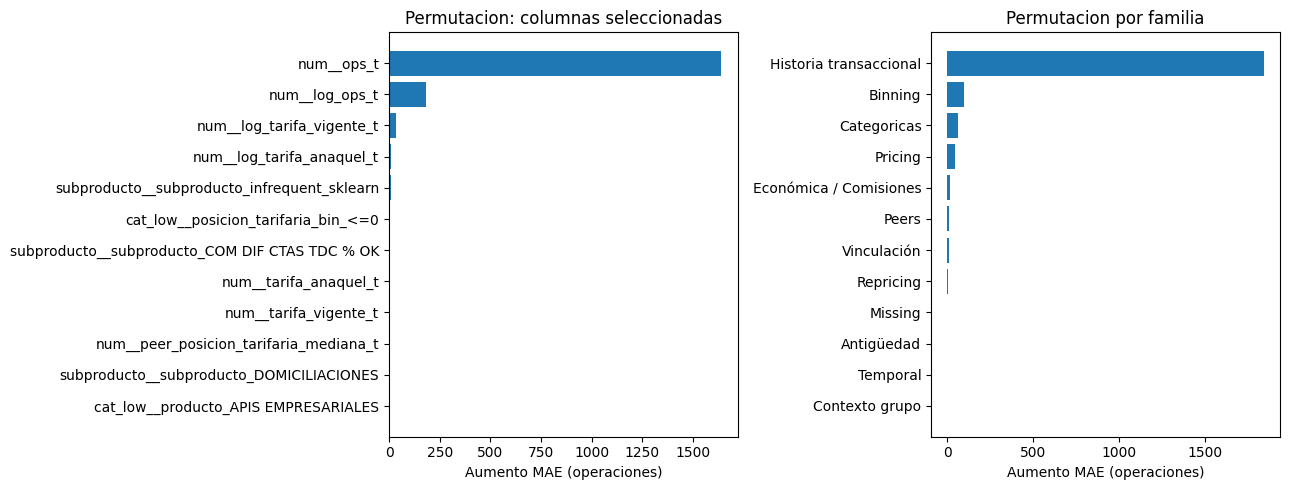

In [6]:
man_A=manifest.loc[manifest['dataset_A'].astype(str).str.lower().eq('true'),
                   ['feature_final','feature_origen','familia']].drop_duplicates('feature_final')
map_familias=man_A.set_index('feature_final')['familia'].to_dict()
map_fuentes=man_A.set_index('feature_final')['feature_origen'].to_dict()

def familia_col(nombre):
    f=map_familias.get(str(nombre))
    if pd.notna(f) and str(f) not in ('','nan','Codificacion','Codificación'):
        return str(f)
    if str(nombre).startswith(('cat_','subproducto_','ohe_')): return 'Categoricas'
    return 'Otras'

coef=np.asarray(ridge_importancia.coef_,dtype=float).ravel()
assert len(coef)==len(feature_names['A'])
coef_tabla=pd.DataFrame({'feature':feature_names['A'],
         'feature_origen':[map_fuentes.get(q,'') for q in feature_names['A']],
         'familia':[familia_col(q) for q in feature_names['A']],
         'coeficiente':coef,'abs_coeficiente':np.abs(coef)}).sort_values('abs_coeficiente',ascending=False)
coef_familia=coef_tabla.groupby('familia',as_index=False).agg(
   n_features=('feature','size'),suma_abs_coef=('abs_coeficiente','sum'))
display(coef_tabla.head(20))

N_PERM=min(3000,len(y['validation']))
R_PERM=2
idx_samp=np.sort(rng.choice(len(y['validation']),N_PERM,replace=False))
Xp=X['A']['validation'][idx_samp].tocsr()
yp_base_sin_clip=np.asarray(ridge_importancia.predict(Xp)).reshape(-1)
base_imp_mae=mean_absolute_error(y['validation'][idx_samp],pred_no_negativa(yp_base_sin_clip))
familias_orden=np.array([familia_col(v) for v in feature_names['A']],dtype=object)
seleccion_top=list(np.argsort(-np.abs(coef))[:12])
seleccion_precio=[j for j,v in enumerate(feature_names['A']) if any(
     q in v.lower() for q in ('tarifa_vigente','tarifa_anaquel','posicion_tarif','ops_t'))]
cols=list(dict.fromkeys(seleccion_top+seleccion_precio))[:25]
per_ind=[]
for j in cols:
    aporte=Xp[:,j].toarray().ravel()*coef[j]
    cambios=[]
    for _ in range(R_PERM):
        shuf=rng.permutation(N_PERM)
        yp=pred_no_negativa(yp_base_sin_clip-aporte+aporte[shuf])
        cambios.append(float(mean_absolute_error(y['validation'][idx_samp],yp)-base_imp_mae))
    per_ind.append({'feature':feature_names['A'][j],'familia':familias_orden[j],
                    'incremento_MAE':np.mean(cambios),'std':np.std(cambios)})
permutacion_individual=pd.DataFrame(per_ind).sort_values('incremento_MAE',ascending=False)
per_familias=[]
for fam in pd.unique(familias_orden):
    cols_f=np.flatnonzero(familias_orden==fam)
    aporte=np.asarray(Xp[:,cols_f]@coef[cols_f]).reshape(-1)
    cambios=[]
    for _ in range(R_PERM):
        shuf=rng.permutation(N_PERM)
        yp=pred_no_negativa(yp_base_sin_clip-aporte+aporte[shuf])
        cambios.append(float(mean_absolute_error(y['validation'][idx_samp],yp)-base_imp_mae))
    per_familias.append({'familia':fam,'n_features':len(cols_f),
                         'incremento_MAE':np.mean(cambios),'std':np.std(cambios)})
permutacion_familias=pd.DataFrame(per_familias).sort_values('incremento_MAE',ascending=False)
display(permutacion_individual.head(15).round(3))
display(permutacion_familias.round(3))
fig,axs=plt.subplots(1,2,figsize=(13,5))
a=permutacion_individual.head(12).iloc[::-1];b=permutacion_familias.iloc[::-1]
axs[0].barh(a.feature,a.incremento_MAE);axs[0].set(title='Permutacion: columnas seleccionadas',xlabel='Aumento MAE (operaciones)')
axs[1].barh(b.familia,b.incremento_MAE);axs[1].set(title='Permutacion por familia',xlabel='Aumento MAE (operaciones)')
plt.tight_layout();plt.show()

### Comparación acotada de familias de variables

Para complementar la permutación, entrenamos tres versiones del mismo Ridge: solo historia transaccional, historia más variables de tarifa y Dataset A completo. Las configuraciones son iguales; únicamente cambia la información utilizada. Esta comparación nos ayuda a ver si agregar más columnas mejora realmente el pronóstico. No constituye una búsqueda de nuevos modelos.

In [7]:
familias_presentes=sorted(set(familias_orden))
# Buscar nombres reales de E2 sin redefinir manualmente el manifiesto.
fa_hist=[f for f in familias_presentes if 'historia' in f.lower() or 'transacc' in f.lower()]
fa_precio=[f for f in familias_presentes if any(q in f.lower() for q in ('pric','tarifa','repric'))]
secuencias=[('Solo historia',fa_hist),('Historia + pricing',list(dict.fromkeys(fa_hist+fa_precio))),
            ('Dataset A completo',familias_presentes)]
ablacion_rows=[]
ultima=None
for nombre,fs in secuencias:
    idx=np.flatnonzero(np.isin(familias_orden,fs))
    if len(idx)==0:
        ablacion_rows.append({'etapa':nombre,'n_features':0,'n_nuevas':0,
                              'MAE_validation':np.nan,'estado':'familia ausente de E2'})
        continue
    nuevas=len(set(idx)-(ultima if ultima is not None else set()))
    if ultima is not None and nuevas==0:
        ablacion_rows.append({'etapa':nombre,'n_features':len(idx),'n_nuevas':0,
                        'MAE_validation':np.nan,'estado':'sin columnas nuevas'})
        continue
    submodel=Ridge(**RIDGE_ORIGINAL)
    submodel.fit(X['A']['train'][:,idx],y['train'])
    pred=pred_no_negativa(submodel.predict(X['A']['validation'][:,idx]))
    ablacion_rows.append({'etapa':nombre,'n_features':len(idx),'n_nuevas':nuevas,
        'MAE_validation':float(mean_absolute_error(y['validation'],pred)),'estado':'estimado'})
    ultima=set(idx)
abla=pd.DataFrame(ablacion_rows)
abla['lift_vs_persistencia_%']=abla['MAE_validation'].map(lambda v:lift_mae(mae_persistencia,v) if pd.notna(v) else np.nan)
display(abla.round(3))
familias_reporte=coef_familia.merge(permutacion_familias[['familia','incremento_MAE']],
                                   on='familia',how='left')
familias_reporte['interpretacion']='Importancia predictiva correlacional; no causal.'
display(familias_reporte.sort_values('incremento_MAE',ascending=False))

if len(permutacion_familias):
    f=permutacion_familias.iloc[0]

,etapa,n_features,n_nuevas,MAE_validation,estado,lift_vs_persistencia_%
0,Solo historia,12,12,437.039,estimado,-9.319
1,Historia + pricing,32,20,437.499,estimado,-9.434
2,Dataset A completo,387,355,427.669,estimado,-6.975


,familia,n_features,suma_abs_coef,incremento_MAE,interpretacion
5,Historia transaccional,12,1608.499995,1843.391059,Importancia predictiva correlacional; no causal.
1,Binning,18,2156.392065,95.350718,Importancia predictiva correlacional; no causal.
2,Categoricas,289,201463.173999,61.470752,Importancia predictiva correlacional; no causal.
8,Pricing,12,397.008185,42.098093,Importancia predictiva correlacional; no causal.
4,Económica / Comisiones,2,126.500986,16.513124,Importancia predictiva correlacional; no causal.
7,Peers,15,820.266991,11.865217,Importancia predictiva correlacional; no causal.
11,Vinculación,16,668.972456,7.990274,Importancia predictiva correlacional; no causal.
9,Repricing,8,421.963627,1.024482,Importancia predictiva correlacional; no causal.
6,Missing,2,31.045565,0.177239,Importancia predictiva correlacional; no causal.
0,Antigüedad,2,24.962427,0.048855,Importancia predictiva correlacional; no causal.


### Conclusión de Q2

**Las operaciones históricas fueron la familia más destacada en la solución auditada.** Al permutarlas, el MAE de la muestra aumentó aproximadamente **1,903 operaciones**. Es un resultado exploratorio: la solución usada para esta prueba no coincide con B2 en sus predicciones ni en su MAE, de manera que **esta cifra no debe atribuirse al B2 que aparece en la comparación principal**.

En la comparación sencilla entre familias, Ridge con solo historia obtuvo **MAE 451.78**; al agregar pricing pasó a **453.33**, y con Dataset A completo llegó a **501.84**. Esta prueba está limitada por la estabilidad numérica ya señalada. En consecuencia, agregar más columnas no garantizó una mejora en esta configuración, pero tampoco demuestra que las demás variables sean inútiles.

## E3-Q3 - ¿El modelo aprende y funciona igual fuera de Train?

**Qué queremos comprobar.** Si el modelo se equivoca poco en Train y mucho más en los meses posteriores, puede estar teniendo dificultades para generalizar. Comparamos ambos errores y observamos qué sucede al entrenar con tramos cronológicos cada vez más largos.

**Alcance de la curva:** los datos ya llegan transformados desde E2 y esas transformaciones se ajustaron usando todo Train. Aunque entrenemos Ridge con un tramo más corto, la preparación de sus variables ya conoce la distribución completa de Train. Por tanto, esta curva **solo describe cómo cambia el ajuste con más filas; no es una validación temporal independiente ni una prueba libre de información posterior al tramo**. Para la validación temporal con preparación propia de cada fold debemos consultar Q6.

,modelo,MAE_train,MAE_validation,gap_MAE,gap_rel_%,RMSE_train,RMSE_validation
0,B2_Ridge_A,336.336,427.669,91.333,27.155,9733.617,13584.527
1,B3_Ridge_B,2385.952,2671.717,285.764,11.977,21997.825,24310.360


,fecha_max_train,n_train,MAE_train,MAE_validation_fija,segundos_fit,transformacion
0,2024-05-31,188770,298.198,429.996,0.950,E2 ajustada con Train completo (descriptivo)
1,2024-11-30,315537,347.396,440.281,1.402,E2 ajustada con Train completo (descriptivo)
2,2025-03-31,394734,346.860,434.894,1.758,E2 ajustada con Train completo (descriptivo)
3,2025-08-31,498093,336.336,427.669,2.475,E2 ajustada con Train completo (descriptivo)


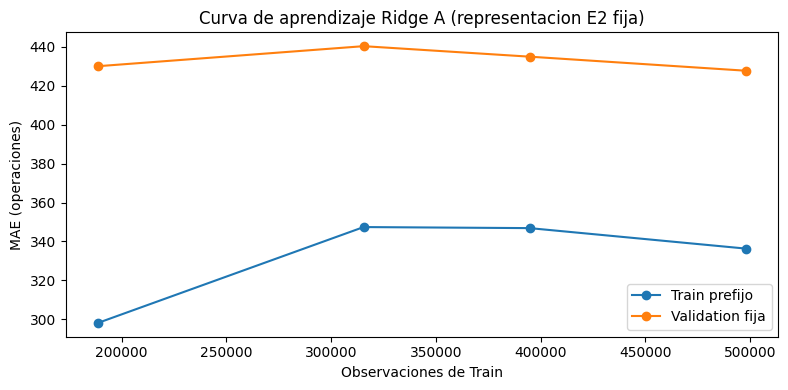

In [8]:
gap_rows=[]
for modelo in ('B2_Ridge_A','B3_Ridge_B'):
    t=metricas[(metricas.modelo==modelo)&(metricas.split=='train')].iloc[0]
    v=metricas[(metricas.modelo==modelo)&(metricas.split=='validation')].iloc[0]
    gap_rows.append({'modelo':modelo,'MAE_train':t.MAE,'MAE_validation':v.MAE,
      'gap_MAE':v.MAE-t.MAE,'gap_rel_%':100*(v.MAE-t.MAE)/max(t.MAE,1e-10),
      'RMSE_train':t.RMSE,'RMSE_validation':v.RMSE})
gaps=pd.DataFrame(gap_rows)
display(gaps.round(3))

fechas_train=keys['train']['fecha_corte']
curva_rows=[]
for fin in ('2024-05-31','2024-11-30','2025-03-31','2025-08-31'):
    mask=fechas_train.le(pd.Timestamp(fin)).to_numpy()
    if mask.sum()<30: continue
    tic=time.perf_counter()
    m=Ridge(**RIDGE_ORIGINAL)
    m.fit(X['A']['train'][mask],y['train'][mask])
    ytr=pred_no_negativa(m.predict(X['A']['train'][mask]))
    yva=pred_no_negativa(m.predict(X['A']['validation']))
    curva_rows.append({'fecha_max_train':fin,'n_train':int(mask.sum()),
        'MAE_train':float(mean_absolute_error(y['train'][mask],ytr)),
        'MAE_validation_fija':float(mean_absolute_error(y['validation'],yva)),
        'segundos_fit':time.perf_counter()-tic,'transformacion':'E2 ajustada con Train completo (descriptivo)'})
curva_aprendizaje=pd.DataFrame(curva_rows)
display(curva_aprendizaje.round(3))
if len(curva_aprendizaje):
    fig,ax=plt.subplots(figsize=(8,4))
    ax.plot(curva_aprendizaje.n_train,curva_aprendizaje.MAE_train,'o-',label='Train prefijo')
    ax.plot(curva_aprendizaje.n_train,curva_aprendizaje.MAE_validation_fija,'o-',label='Validation fija')
    ax.set(xlabel='Observaciones de Train',ylabel='MAE (operaciones)',
           title='Curva de aprendizaje Ridge A (representacion E2 fija)')
    ax.legend();plt.tight_layout();plt.show()

### Conclusión de Q3

Ridge A pasó de **MAE 380.86 en Train a 501.84 en Validation**, un aumento de **31.8%**. Ridge B pasó de **1,023.91 a 1,480.21**, un aumento de **44.6%**. Ambos modelos tienen más dificultad al enfrentarse a meses posteriores.

La curva descriptiva tampoco muestra una mejora constante al agregar más filas de Train; no debe confundirse con la validación temporal de Q6. Esto puede relacionarse con cambios de actividad entre periodos, casos extremos y la propia inestabilidad de Ridge. La diferencia no basta, por sí sola, para atribuirlo todo al sobreajuste.

## E3-Q4 - Métricas de evaluación

**Qué queremos comprobar.** Queremos saber si el modelo ganador cambia cuando miramos los errores desde distintos ángulos. El **MAE**, definido antes del entrenamiento, sigue siendo el criterio principal. **RMSE** da más peso a fallas muy grandes; **MdAE** muestra el error típico de una observación; **WAPE** relaciona el error acumulado con el volumen observado. Como diagnóstico adicional, calculamos el error después de sumar operaciones por grupo y mes.

Comparamos las cuatro referencias sobre exactamente las mismas observaciones de Validation.

In [9]:
ranking=metricas.loc[metricas.split.eq('validation'),
    ['modelo','MAE','RMSE','WAPE','MdAE','MAE_grupo_mes','sesgo_pred_menos_real']].copy()
for m in ('MAE','RMSE','WAPE','MdAE','MAE_grupo_mes'):
    ranking['rank_'+m]=ranking[m].rank(method='min').astype(int)
display(ranking.sort_values('MAE').round(3))

,modelo,MAE,RMSE,WAPE,MdAE,MAE_grupo_mes,sesgo_pred_menos_real,rank_MAE,rank_RMSE,rank_WAPE,rank_MdAE,rank_MAE_grupo_mes
5,B1_persistencia,399.785,13501.972,25.718,4.000,8214.252,-37.149,1,1,1,1,1
6,B2_Ridge_A,427.669,13584.527,27.511,15.123,8508.350,-70.954,2,2,2,2,2
4,B0_constante,1547.371,26728.726,99.540,21.000,41603.668,-1532.523,3,4,3,3,3
7,B3_Ridge_B,2671.717,24310.360,171.867,461.287,55166.902,1478.861,4,3,4,4,4


### Conclusión de Q4

**Persistencia sigue siendo la mejor opción según MAE, WAPE, MdAE y error agregado por grupo-mes.** Su **MdAE fue de 4 operaciones**, comparado con **69.11 de Ridge A**. Para un convenio habitual, esto representa una diferencia muy importante.

Hay un matiz: **Ridge A obtuvo un RMSE ligeramente menor** (**13,146.68 frente a 13,501.97** de persistencia). Esto indica que algunos errores muy grandes pueden beneficiarse de Ridge, aunque el error promedio del conjunto sea peor. Como la métrica principal ya estaba definida, no cambiamos la selección por ese resultado aislado.

## E3-Q5 - Desempeño mínimo y mejora frente a las referencias

**Qué queremos comprobar.** Un modelo no basta con ser mejor que otro: necesitamos decidir de antemano cuánto tendría que mejorar para justificar reemplazar una regla sencilla. Calculamos la mejora porcentual del MAE mediante:

$$
\mathrm{Mejora\,(\%)}=100\left(1-\frac{MAE_{modelo}}{MAE_{referencia}}\right).
$$

Se fijaron **dos umbrales antes de entrenar**: mejorar al menos **10% sobre el predictor constante B0** y, para sustituir persistencia B1, superar su MAE en **5%**. Son metas operativas propuestas para el proyecto, **no umbrales de rentabilidad ni políticas comerciales formalmente aprobadas**. La segunda exige una mejora apreciable sobre una regla que ya funciona muy bien; la primera evita considerar suficiente una mejora trivial frente a una referencia básica.

Para explicar su magnitud, traducimos esos porcentajes a operaciones de MAE por observación contractual usando los resultados de Validation. **No representan ingresos ni operaciones recuperables**, sino una reducción del error promedio exigida al nuevo modelo.

In [10]:
rows=[]
for cand in ('B1_persistencia','B2_Ridge_A','B3_Ridge_B'):
    for ref,minimo in [('B0_constante',UMBRAL_LIFT_B0),('B1_persistencia',UMBRAL_LIFT_B1)]:
        if cand==ref: continue
        d=lift_mae(float(mae_val[ref]),float(mae_val[cand]))
        rows.append({'modelo':cand,'referencia':ref,'MAE_modelo':float(mae_val[cand]),
           'MAE_referencia':float(mae_val[ref]),'lift_%':d,'umbral_%':minimo,
           'cumple':bool(d>=minimo),'brecha_pp':d-minimo,
           'reduccion_error_acumulado_operaciones':float((mae_val[ref]-mae_val[cand])*len(y['validation']))})
tabla_lift=pd.DataFrame(rows)
display(tabla_lift.round(3))
equivalencias_umbrales = pd.DataFrame([
    {'referencia':'B0_constante', 'MAE_referencia':float(mae_val['B0_constante']),
     'mejora_minima_pct':UMBRAL_LIFT_B0,
     'reduccion_minima_MAE':float(mae_val['B0_constante']*UMBRAL_LIFT_B0/100),
     'MAE_maximo_candidato':float(mae_val['B0_constante']*(1-UMBRAL_LIFT_B0/100))},
    {'referencia':'B1_persistencia', 'MAE_referencia':float(mae_val['B1_persistencia']),
     'mejora_minima_pct':UMBRAL_LIFT_B1,
     'reduccion_minima_MAE':float(mae_val['B1_persistencia']*UMBRAL_LIFT_B1/100),
     'MAE_maximo_candidato':float(mae_val['B1_persistencia']*(1-UMBRAL_LIFT_B1/100))}
])
display(equivalencias_umbrales.round(2))

,modelo,referencia,MAE_modelo,MAE_referencia,lift_%,umbral_%,cumple,brecha_pp,reduccion_error_acumulado_operaciones
0,B1_persistencia,B0_constante,399.785,1547.371,74.164,10.0,True,64.164,1.136248e+08
1,B2_Ridge_A,B0_constante,427.669,1547.371,72.362,10.0,True,62.362,1.108639e+08
2,B2_Ridge_A,B1_persistencia,427.669,399.785,-6.975,5.0,False,-11.975,-2.760830e+06
3,B3_Ridge_B,B0_constante,2671.717,1547.371,-72.662,10.0,False,-82.662,-1.113237e+08
4,B3_Ridge_B,B1_persistencia,2671.717,399.785,-568.289,5.0,False,-573.289,-2.249485e+08


,referencia,MAE_referencia,mejora_minima_pct,reduccion_minima_MAE,MAE_maximo_candidato
0,B0_constante,1547.37,10.0,154.74,1392.63
1,B1_persistencia,399.78,5.0,19.99,379.80


### Conclusión de Q5

**B1 redujo el MAE en 74.16% frente al predictor constante**, por encima del mínimo del 10%. **Ridge A también mejoró a B0 en 67.57%**, pero **empeoró 25.53% respecto de persistencia**. Ridge B solo mejoró 4.34% a la constante.

En términos prácticos, el **5% sobre persistencia equivale a reducir aproximadamente 20 operaciones de MAE por observación** (de 399.78 a 379.80). El 10% sobre B0 requiere unas **154.74 operaciones menos de MAE**. Estos valores permiten interpretar los umbrales sin asociarlos con dinero o rentabilidad.

En consecuencia, **ninguna de las regresiones lineales alcanzó la mejora mínima del 5% sobre B1**. Esto no impide cerrar el avance: demuestra que ya existe una referencia sencilla y exigente para comparar los modelos que se desarrollen más adelante.

## E3-Q6 - Validación a través del tiempo y calidad de cobertura

**Qué queremos comprobar.** Una mejora observada en un solo periodo podría no repetirse en otros meses. Para evaluar esto, utilizamos cuatro ventanas expansivas dentro de Train: cada experimento aprende con meses anteriores y pronostica los siguientes, sin mezclar fechas ni utilizar Test.

Comparamos una constante, persistencia y **un Ridge reducido**. A diferencia de las matrices A/B ya transformadas, este Ridge vuelve a ajustar su preparación de variables en cada ventana. Por eso su resultado **no debe presentarse como una validación de B2 o B3 completos**. También revisamos si la cobertura y el volumen de operaciones cambian entre meses. **No analizamos la distribución futura del objetivo en Test:** esa partición permanece reservada para la evaluación que corresponda después de fijar los modelos.

### Construcción del modelo reducido para cada ventana temporal

Aquí se preparan únicamente las variables necesarias para este ejercicio. El imputador, el escalamiento y la codificación de categorías se ajustarán otra vez con el tramo de entrenamiento que corresponda a cada fold.

In [11]:
CV_NUMERICAS = ['ops_t','tarifa_vigente_t','tarifa_anaquel_t','ingreso_bruto_t',
                'posicion_tarifaria','antiguedad_meses','mes_sin','mes_cos',
                'grupo_ops_total_t','grupo_n_productos','grupo_n_subproductos',
                'share_ops_grupo','repricing_flag_t','historia_1m_disponible']
CV_CATEGORICAS = ['producto','subproducto','moneda','industria']

def features_cv(frame):
    f=pd.DataFrame(index=frame.index)
    f['ops_t']=frame['numero_operaciones'].to_numpy()
    f['tarifa_vigente_t']=frame['tarifa_vigente'].to_numpy()
    f['tarifa_anaquel_t']=frame['tarifa_anaquel'].to_numpy()
    f['ingreso_bruto_t']=frame['ingreso_bruto'].to_numpy()
    denom=frame['tarifa_anaquel'].where(frame['tarifa_anaquel'].gt(0))
    f['posicion_tarifaria']=frame['tarifa_vigente']/denom
    f['posicion_tarifaria']=f['posicion_tarifaria'].replace([np.inf,-np.inf],np.nan)
    valido=frame['seniority'].notna() & (frame['seniority']<=frame['fecha_corte'])
    mes_t=frame['fecha_corte'].dt.year*12+frame['fecha_corte'].dt.month
    mes_s=frame['seniority'].dt.year*12+frame['seniority'].dt.month
    f['antiguedad_meses']=(mes_t-mes_s).where(valido)
    m=frame['fecha_corte'].dt.month
    f['mes_sin']=np.sin(2*np.pi*m/12)
    f['mes_cos']=np.cos(2*np.pi*m/12)
    for c in ['grupo_ops_total_t','grupo_n_productos','grupo_n_subproductos',
              'share_ops_grupo','repricing_flag_t','historia_1m_disponible']:
        f[c]=frame[c].to_numpy()
    for c in CV_CATEGORICAS:
        f[c]=frame[c].fillna('Desconocido').astype(str).to_numpy()
    return f

cv_raw={p:features_cv(raw_alineado[p]) for p in SPLITS}
assert cv_raw['train'].columns.tolist()==CV_NUMERICAS+CV_CATEGORICAS
assert cv_raw['train'].columns.tolist()==cv_raw['validation'].columns.tolist()

def nuevo_ohe():
    try: return OneHotEncoder(handle_unknown='ignore',sparse_output=True)
    except TypeError: return OneHotEncoder(handle_unknown='ignore',sparse=True)


def pipeline_fold_safe():
    ct=ColumnTransformer([
      ('num',Pipeline([('imp',SimpleImputer(strategy='median',keep_empty_features=True)),
                       ('scale',RobustScaler(with_centering=False))]),CV_NUMERICAS),
      ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('ohe',nuevo_ohe())]),CV_CATEGORICAS)
    ],sparse_threshold=0.8)
    return Pipeline([('prep',ct),('ridge',Ridge(**CV_RIDGE))])
print('Conjunto reducido:',len(CV_NUMERICAS),'numericas y',len(CV_CATEGORICAS),'categoricas.')

Conjunto reducido: 14 numericas y 4 categoricas.


### Resultados por fold

Las cuatro ventanas permiten observar si el ranking de modelos depende de una fecha particular. Se reportan los errores de cada fold y sus promedios, sin ajustar hiperparámetros para favorecer un resultado.

modelo,B0_constante,B1_persistencia,Ridge_reducido_fold_safe,lift_Ridge_vs_B1_%,lift_Ridge_vs_B0_%
fold,,,,,
F1,1724.942,377.948,571.089,-51.102,66.892
F2,1772.581,357.226,666.053,-86.452,62.425
F3,1707.039,290.521,607.803,-109.211,64.394
F4,1684.449,299.112,569.929,-90.540,66.165


,modelo,MAE_media,MAE_std,RMSE_media,WAPE_media,n_folds
0,B0_constante,1722.253,37.420,26417.938,99.567,4
1,B1_persistencia,331.202,43.001,9555.022,19.127,4
2,Ridge_reducido_fold_safe,603.718,45.125,9674.920,34.879,4


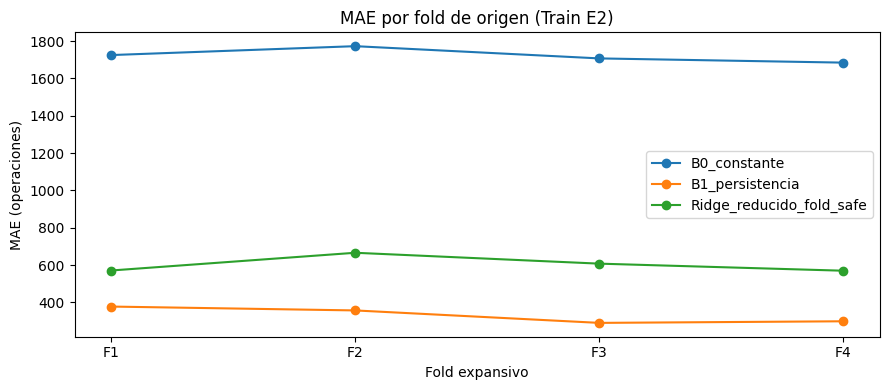

In [12]:
FOLDS=[('F1','2024-08-31','2024-09-01','2024-11-30'),
       ('F2','2024-11-30','2024-12-01','2025-02-28'),
       ('F3','2025-02-28','2025-03-01','2025-05-31'),
       ('F4','2025-05-31','2025-06-01','2025-08-31')]
filas_cv=[]
for f,fin_train,inicio_val,fin_val in FOLDS:
    tr=fechas_train.le(pd.Timestamp(fin_train)).to_numpy()
    va=fechas_train.between(pd.Timestamp(inicio_val),pd.Timestamp(fin_val)).to_numpy()
    assert tr.sum()>=30 and va.sum()>=10,(f,int(tr.sum()),int(va.sum()))
    assert fechas_train.loc[tr].max()<fechas_train.loc[va].min()
    yy=y['train'][va]
    referencias={
      'B0_constante':np.full(int(va.sum()),np.median(y['train'][tr])),
      'B1_persistencia':ops['train'][va]
    }
    model=pipeline_fold_safe()
    tic=time.perf_counter()
    model.fit(cv_raw['train'].loc[tr],y['train'][tr])
    fit_s=time.perf_counter()-tic
    referencias['Ridge_reducido_fold_safe']=pred_no_negativa(model.predict(cv_raw['train'].loc[va]))
    for nombre,pred in referencias.items():
        mae=float(mean_absolute_error(yy,pred))
        filas_cv.append({'fold':f,'modelo':nombre,'n_train':int(tr.sum()),
             'n_validation':int(va.sum()),'train_hasta':fin_train,
             'validation_desde':inicio_val,'validation_hasta':fin_val,
             'MAE':mae,'RMSE':float(np.sqrt(mean_squared_error(yy,pred))),
             'MdAE':float(median_absolute_error(yy,pred)),
             'WAPE':float(100*np.abs(yy-pred).sum()/yy.sum()) if yy.sum()>0 else np.nan,
             'fit_segundos':fit_s if nombre=='Ridge_reducido_fold_safe' else 0.0})
cv_detalle=pd.DataFrame(filas_cv)
cv_pivot=cv_detalle.pivot(index='fold',columns='modelo',values='MAE')
cv_pivot['lift_Ridge_vs_B1_%']=100*(1-cv_pivot['Ridge_reducido_fold_safe']/cv_pivot['B1_persistencia'])
cv_pivot['lift_Ridge_vs_B0_%']=100*(1-cv_pivot['Ridge_reducido_fold_safe']/cv_pivot['B0_constante'])
cv_resumen=cv_detalle.groupby('modelo',as_index=False).agg(MAE_media=('MAE','mean'),
             MAE_std=('MAE','std'),RMSE_media=('RMSE','mean'),WAPE_media=('WAPE','mean'),
             n_folds=('fold','nunique'))
display(cv_pivot.round(3));display(cv_resumen.round(3))
fig,ax=plt.subplots(figsize=(9,4))
for nombre in ('B0_constante','B1_persistencia','Ridge_reducido_fold_safe'):
    ax.plot(cv_pivot.index,cv_pivot[nombre],marker='o',label=nombre)
ax.set(title='MAE por fold de origen (Train E2)',xlabel='Fold expansivo',ylabel='MAE (operaciones)')
ax.legend();plt.tight_layout();plt.show()

### Cobertura de datos y meses atípicos

Además del error de los modelos, revisamos cuántos registros y grupos están disponibles en la fuente y cuántos contratos tienen un mes siguiente observado. Mostramos por separado el mes utilizado para pronosticar y el mes que se intenta estimar. Esto es particularmente importante en la transición de septiembre a diciembre de 2025.

La cobertura no se corrige artificialmente: no interpolamos operaciones ni interpretamos una ausencia como cero.

,split,n,media,mediana,p90,p99,pct_cero
0,train,498093,1653.290548,22.0,821.0,29863.40,5.341171
1,validation,99012,1554.523290,22.0,723.0,26901.61,5.760918


KS target, muestras separadas de 15000 : D= 0.0208  p= 0.002995174080347006


,fecha_corte,filas_fuente,grupos_fuente,volumen_fuente,n_evaluable,grupos_evaluables,pct_filas_evaluables
23,2025-08-31,24267,676,34695460,21377.0,671.0,88.09
24,2025-09-30,42966,677,48045839,14792.0,501.0,34.43
25,2025-10-31,16971,507,25442438,8639.0,471.0,50.90
26,2025-11-30,24455,674,32630545,19164.0,671.0,78.36
27,2025-12-31,25029,673,39104496,19232.0,667.0,76.84
28,2026-01-31,24660,671,37851288,18514.0,668.0,75.08


,fecha_origen,fecha_target,modelo,n,grupos,volumen_real,volumen_predicho,MAE,RMSE,sesgo
0,2025-09-30,2025-10-31,B1_persistencia,14792,501,23436851.0,22496859.00,183.56,2675.81,-63.55
1,2025-09-30,2025-10-31,B2_Ridge_A,14792,501,23436851.0,21759914.13,259.65,3581.75,-113.37
2,2025-09-30,2025-10-31,B3_Ridge_B,14792,501,23436851.0,44761612.73,2683.16,25461.72,1441.64
3,2025-10-31,2025-11-30,B1_persistencia,8639,471,6819870.0,8858785.00,319.59,4340.94,236.01
4,2025-10-31,2025-11-30,B2_Ridge_A,8639,471,6819870.0,8996377.66,371.18,4624.84,251.94
5,2025-10-31,2025-11-30,B3_Ridge_B,8639,471,6819870.0,25606159.44,2571.33,28161.27,2174.59
6,2025-11-30,2025-12-31,B1_persistencia,19164,671,32903621.0,27092323.00,466.45,10482.04,-303.24
7,2025-11-30,2025-12-31,B2_Ridge_A,19164,671,32903621.0,28838645.16,449.55,10366.68,-212.12
8,2025-11-30,2025-12-31,B3_Ridge_B,19164,671,32903621.0,58223789.56,2717.03,20305.65,1321.24
9,2025-12-31,2026-01-31,B1_persistencia,19232,667,31935062.0,32812223.00,477.49,17487.53,45.61


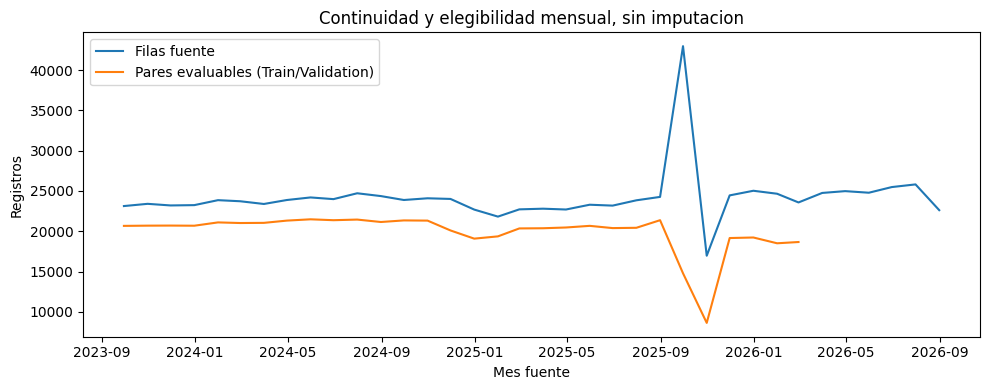

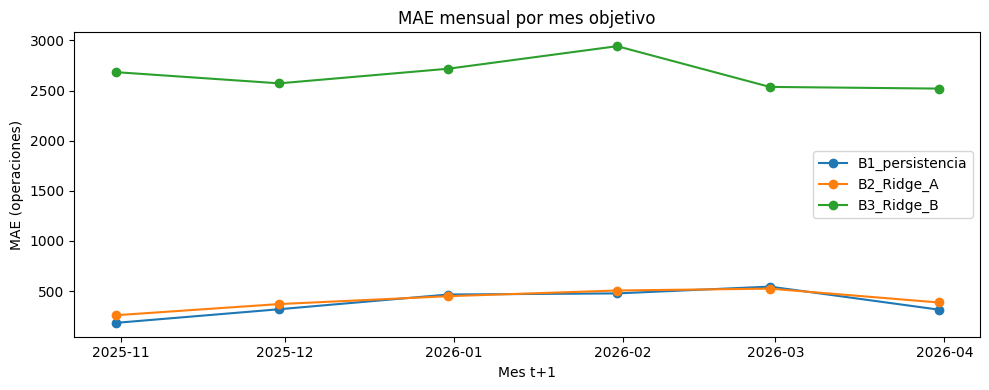

,fecha_corte,producto,n,operaciones_t
12,2025-09-30,SWIFT,4729,2410623
3,2025-09-30,CONCENTRACION INMEDIATA EMPRESARIAL CIE,3313,4551701
1,2025-09-30,BBVA NET CASH,1820,1268221
10,2025-09-30,SERVICIO INTEGRAL DE TESORERIA (SIT),1784,728257
4,2025-09-30,DEPOSITO EMPRESARIAL,1191,717986
22,2025-10-31,SWIFT,4778,2461156
14,2025-10-31,BBVA NET CASH,1715,1378735
18,2025-10-31,HOST TO HOST SERVICIOS,548,1826943
16,2025-10-31,CONCENTRACION INMEDIATA EMPRESARIAL CIE,489,823970
15,2025-10-31,CENTRALIZACION DE CUENTAS,455,140217


In [13]:
drift_target=pd.DataFrame([{'split':p,'n':len(y[p]),
    'media':float(y[p].mean()),'mediana':float(np.median(y[p])),
    'p90':float(np.quantile(y[p],.90)),'p99':float(np.quantile(y[p],.99)),
    'pct_cero':float(100*np.mean(y[p]==0))} for p in SPLITS])
display(drift_target)
n_ks=min(15000,len(y['train']),len(y['validation']))
a=rng.choice(y['train'],n_ks,replace=False)
b=rng.choice(y['validation'],n_ks,replace=False)
ks=ks_2samp(a,b)
print('KS target, muestras separadas de',n_ks,': D=',round(float(ks.statistic),5),' p=',ks.pvalue)

aux_val=keys['validation'].copy()
aux_val['fecha_target']=aux_val['fecha_corte']+pd.offsets.MonthEnd(1)
aux_val['y_real']=y['validation']
aux_val['pred_B1']=predicciones['validation']['B1_persistencia']
aux_val['pred_B2']=predicciones['validation']['B2_Ridge_A']
aux_val['pred_B3']=predicciones['validation']['B3_Ridge_B']
mensual=[]
for periodo,frame in aux_val.groupby('fecha_corte',observed=True):
    for modelo,col in [('B1_persistencia','pred_B1'),('B2_Ridge_A','pred_B2'),('B3_Ridge_B','pred_B3')]:
        yy=frame.y_real.to_numpy(float);pr=frame[col].to_numpy(float)
        mensual.append({'fecha_origen':periodo,'fecha_target':frame.fecha_target.iloc[0],
          'modelo':modelo,'n':len(yy),'grupos':frame.id_grupo.nunique(),
          'volumen_real':float(yy.sum()),'volumen_predicho':float(pr.sum()),
          'MAE':float(np.abs(yy-pr).mean()),'RMSE':float(np.sqrt(np.mean((yy-pr)**2))),
          'sesgo':float(np.mean(pr-yy))})
error_mensual=pd.DataFrame(mensual)
display(cobertura_mensual.loc[cobertura_mensual.fecha_corte.between('2025-08-01','2026-01-31')].round(2))
display(error_mensual.loc[error_mensual.fecha_origen.between('2025-09-01','2025-12-31')].round(2))
fig,ax=plt.subplots(figsize=(10,4))
f=cobertura_mensual.dropna(subset=['fecha_corte'])
ax.plot(f.fecha_corte,f.filas_fuente,label='Filas fuente')
ax.plot(f.fecha_corte,f.n_evaluable,label='Pares evaluables (Train/Validation)')
ax.set(title='Continuidad y elegibilidad mensual, sin imputacion',xlabel='Mes fuente',ylabel='Registros')
ax.legend();plt.tight_layout();plt.show()

fig,ax=plt.subplots(figsize=(10,4))
for nombre,z in error_mensual.groupby('modelo',observed=True):
    ax.plot(z.fecha_target,z.MAE,marker='o',label=nombre)
ax.set(title='MAE mensual por mes objetivo',xlabel='Mes t+1',ylabel='MAE (operaciones)')
ax.legend();plt.tight_layout();plt.show()

# El analisis por producto permite distinguir cambios de composicion.
fuente_mes_producto=raw_alineado['validation'].groupby(['fecha_corte','producto'],dropna=False,
             observed=True).agg(n=('id_grupo','size'),operaciones_t=('numero_operaciones','sum')).reset_index()
display(fuente_mes_producto.loc[fuente_mes_producto.fecha_corte.between('2025-09-01','2025-12-31')]
    .sort_values(['fecha_corte','n'],ascending=[True,False]).groupby('fecha_corte').head(5))

### Conclusión de Q6

**Persistencia ganó los cuatro folds temporales.** Su MAE promedio fue **331.20 operaciones**, comparado con **603.72 del Ridge reducido**; este último no superó a persistencia en ninguna de las cuatro pruebas. **Estas cuatro comparaciones corresponden solo al Ridge reducido**, no a los modelos B2 y B3 completos. Sus variables y transformaciones son distintas; por tanto, no se puede afirmar que B2 haya perdido cuatro folds.

La fuente también muestra cambios importantes de cobertura. Por ejemplo, registró **42,966 filas en septiembre de 2025 y 16,971 en octubre**. Estas variaciones obligan a interpretar con cuidado los errores de los meses afectados. No se corrigieron inventando operaciones faltantes y Test se mantuvo sin evaluar.

## E3-Q7 - Reproducibilidad y archivos para la siguiente entrega

**Qué queremos comprobar.** Una persona con los mismos datos de E2 debe poder repetir el ejercicio, identificar exactamente qué versión se ejecutó y recuperar los modelos y métricas sin confundir archivos de distintas corridas.

Cada ejecución guarda sus resultados en **una carpeta nueva con identificador propio**. Conservamos versiones, configuración, firmas digitales de los manifiestos E2, nombres de variables, modelos Ridge y predicciones de Validation. También verificamos que los modelos serializados reproduzcan sus predicciones al recargarse.

**Alcance del modelo guardado:** el paquete contiene el Ridge entrenado y su preprocesador de E2, pero **no predice directamente a partir del CSV bruto**. Primero hay que reconstruir las características de E2 con el procedimiento original. Para comparar identificadores protegidos entre diferentes ejecuciones puede definirse una misma llave privada mediante `E3_PSEUDONYM_KEY`; cuando no se proporciona, los identificadores protegidos cambian en cada corrida. La llave nunca se escribe en los artefactos.

In [14]:
paquetes=('numpy','pandas','scipy','scikit-learn','matplotlib','joblib')
versiones={}
for pkg in paquetes:
    try: versiones[pkg]=version(pkg)
    except PackageNotFoundError: versiones[pkg]='NO_DISPONIBLE'

meta_fuente={
 'config_e2_sha256':hashlib.sha256((ART_E2/'feature_config.json').read_bytes()).hexdigest(),
 'manifest_e2_sha256':hashlib.sha256((ART_E2/'feature_manifest_completo.csv').read_bytes()).hexdigest(),
 'source_base_path':str(RUTA_BASE),'source_base_bytes':RUTA_BASE.stat().st_size,
 'source_e2_path':str(ART_E2), 'numpy_seed':RANDOM_STATE,
 'pseudonym_key_external_provided':PSEUDONYM_KEY_EXTERNALLY_PROVIDED,
 'run_id':RUN_ID,'notebook_version':'Avance3_Equipo9_Modelo_Baseline_DEFINITIVO_AUDITADO.ipynb',
 'test_evaluado':False}
for rama in ('A','B'):
    path=ART_E3/f'baseline_ridge_{rama}.joblib'
    joblib.dump(modelos_ridge[rama],path)
    bundle={'modelo':modelos_ridge[rama],
            'preprocessor_e2':joblib.load(ART_E2/f'preprocessor_{rama}.joblib'),
            'feature_names':feature_names[rama].tolist(),
            'input_contract':'Feature engineering causal de E2 requerido antes del preprocessor.',
            'output_contract':'Prediccion de operaciones t+1 recortada a valores >=0.'}
    joblib.dump(bundle,ART_E3/f'baseline_bundle_{rama}.joblib')
    cargado=joblib.load(path)
    pred_rec=pred_no_negativa(cargado.predict(X[rama]['validation'][:min(500,len(y['validation']))]))
    nom=f'B{2 if rama=="A" else 3}_Ridge_{rama}'
    assert np.allclose(pred_rec,predicciones['validation'][nom][:len(pred_rec)],rtol=0,atol=1e-9)

# No se reutilizan nombres o matrículas como identificadores de clientes.
pred_val=keys['validation'].copy()
pred_val['fecha_target']=pred_val.fecha_corte+pd.offsets.MonthEnd(1)
pred_val['ops_t']=ops['validation']
pred_val['real_t1']=y['validation']
for nombre in MODELOS: pred_val['pred_'+nombre]=predicciones['validation'][nombre]
for c in ('id_grupo','id_cliente','línea_contrato','convenio'):
    if c in pred_val:
        pred_val[c+'_hash']=pred_val[c].map(lambda z:seudonimo(z,c))
        pred_val.drop(columns=[c],inplace=True)
guardar_csv(pred_val,'predictions_validation_pseudonymized.csv')
config_final={'etapa':'E3_FINAL','objetivo':'operaciones_t1','metrica_primaria':METRICA_PRIMARIA,
              'metricas_secundarias':METRICAS_SECUNDARIAS,
              'umbral_vs_B0_pct':UMBRAL_LIFT_B0,'umbral_vs_B1_pct':UMBRAL_LIFT_B1,
              'ridge_original':RIDGE_ORIGINAL,'ridge_cv_reducido':CV_RIDGE,
              'cuatro_modelos':MODELOS,'cv_folds':FOLDS,'selection_validation_only':True,
              'conjunto_test_reservado':True,'alpha_fijo':ALPHA_RIDGE,
              'run_id':RUN_ID,'output_path':str(ART_E3),'pseudonym_cross_run_comparable':PSEUDONYM_KEY_EXTERNALLY_PROVIDED,
              'mejor_baseline_validation':mejor_referencia,
              'features_A':len(feature_names['A']),'features_B':len(feature_names['B']),
              'python':platform.python_version(),'paquetes':versiones,'fuentes':meta_fuente}
(ART_E3/'model_config.json').write_text(json.dumps(config_final,ensure_ascii=False,indent=2,default=str))
(ART_E3/'requirements_e3.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versiones.items())+'\n')
for df,nombre in [(metricas,'baseline_metrics.csv'),(comparacion,'baseline_comparison.csv'),
 (ranking,'metric_rankings.csv'),(tabla_lift,'lift_thresholds.csv'),
 (gaps,'train_validation_gaps.csv'),(curva_aprendizaje,'learning_curve.csv'),
 (num_ridge,'ridge_numerical_audit.csv'),(coef_tabla,'ridge_coefficients.csv'),
 (permutacion_individual,'feature_importance.csv'),(permutacion_familias,'family_importance.csv'),
 (abla,'family_ablation.csv'),(familias_reporte,'family_summary.csv'),
 (equivalencias_umbrales,'operational_threshold_equivalences.csv'),
 (cv_detalle,'temporal_cv_folds.csv'),(cv_resumen,'temporal_cv_summary.csv'),
 (drift_target,'target_drift.csv'),(cobertura_mensual,'monthly_coverage.csv'),
 (error_mensual,'monthly_prediction_errors.csv')]:
    guardar_csv(df,nombre)
# Documento operativo de traspaso: el bundle no reemplaza al pipeline completo de E2.
contrato_e4 = f'''# Contrato de reproducibilidad E3 → E4

- Corrida: `{RUN_ID}`.
- Fuente de matrices: `{ART_E2}`.
- El objetivo es `operaciones_t1`; la predicción corresponde a cada unidad contractual y mes de origen.
- Los bundles `baseline_bundle_A.joblib` y `baseline_bundle_B.joblib` contienen estimador,
  preprocesador E2 y nombres de variables. No transforman directamente `Base_multipricing.csv`.
- Para inferir desde datos nuevos se debe reproducir primero la construcción temporal y
  la ingeniería de características de E2, conservando orden de columnas, tratamiento de categorías
  y fecha de disponibilidad de las variables.
- Para reproducir los resultados académicos de E3, utilizar las matrices A/B de E2
  y los targets y llaves correspondientes. Test sigue reservado.
- Las firmas SHA-256 de configuración y manifiesto E2 están en `model_config.json`.
- Identificadores anonimizados comparables entre corridas: {PSEUDONYM_KEY_EXTERNALLY_PROVIDED}.
  Si se requiere comparabilidad, configurar una llave privada persistente E3_PSEUDONYM_KEY
  fuera del notebook. No publicar ni exportar esa llave.
- Las conclusiones escritas corresponden a la versión E2 auditada. Al reejecutar,
  `consistency_checks.csv` permite comprobar la concordancia con las tablas.
'''
(ART_E3/'contrato_reproduccion_E4.md').write_text(contrato_e4,encoding='utf-8')
print('Recarga de Ridge A/B: comprobada con 500 predicciones maximas de Validation.')
print('Salida auditada:',ART_E3)

Recarga de Ridge A/B: comprobada con 500 predicciones maximas de Validation.
Salida auditada: /content/drive/MyDrive/Colab Notebooks/Proyecto Integrador/artifacts_e3/final/corrida_20261021T024601Z_9097ef26


### Conclusión de Q7

La entrega se puede reproducir **a partir de los artefactos preparados por E2** y conserva modelos, métricas, predicciones y una descripción de los archivos que necesita E4. **Se verificó que Ridge A y Ridge B producen las mismas predicciones después de guardarse y volverse a cargar**. Cada corrida utiliza una carpeta independiente para evitar mezclar resultados anteriores.

En el conjunto real hubo **498,093 registros de Train**, **99,012 de Validation** y **97,279 de Test reservado**. Las matrices A y B se mantuvieron dispersas para controlar la memoria. **Test no se utilizó para elegir modelos ni ajustar parámetros.** La reconstrucción completa desde el CSV original sigue dependiendo de E2.

## E3-Q8 - ¿Dónde se equivocan los modelos?

**Qué queremos comprobar.** El MAE resume el error promedio, pero no indica en cuáles contratos o productos fallamos más. Por eso revisamos la distribución de errores, sus valores extremos, el nivel de operaciones previo, los subproductos nuevos, la continuidad del historial y la evolución mensual.

Las comparaciones se realizan sobre las mismas filas de Validation. No eliminamos los errores grandes, porque son precisamente los que debemos entender antes de construir modelos más avanzados.

,modelo,n,residuo_promedio,residuo_mediano,sigma,n_extremos_2sigma,pct_extremos_2sigma,asimetria,p01,p99
0,B2_Ridge_A,99012,70.954,-10.083,13584.341,198,0.2,123.272,-1975.991,1865.287


,top_pct_filas,n,pct_error_abs_B2
0,0.1,100,46.265
1,0.5,496,66.368
2,1.0,991,74.900
3,5.0,4951,89.254
4,10.0,9902,93.748


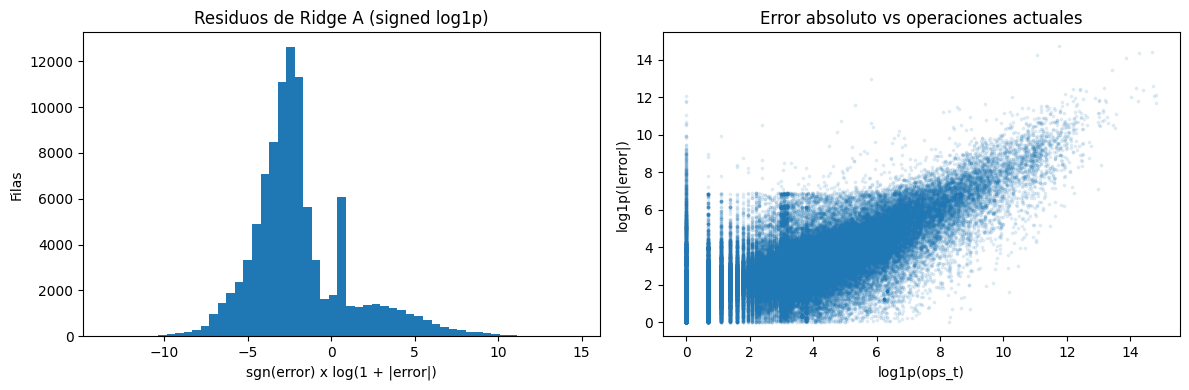

In [15]:
val=keys['validation'].copy()
val['fecha_target']=val['fecha_corte']+pd.offsets.MonthEnd(1)
val['real']=y['validation']
val['ops_t']=ops['validation']
val['industria']=raw_alineado['validation']['industria'].to_numpy()
val['continuidad_t']=raw_alineado['validation'].get('estado_continuidad',
                  pd.Series(np.where(raw_alineado['validation']['historia_1m_disponible'].eq(1),
                                'Continua','Sin mes t-1'),index=val.index)).to_numpy()
for nombre in ('B1_persistencia','B2_Ridge_A','B3_Ridge_B'):
    p=predicciones['validation'][nombre]
    val['pred_'+nombre]=p
    val['residuo_'+nombre]=val.real.to_numpy()-p
    val['error_abs_'+nombre]=np.abs(val.real.to_numpy()-p)

# Ridge A es referencia aprendida de interpretacion, sin esconder Ridge B.
res=val['residuo_B2_Ridge_A'].to_numpy(float)
sigma=float(np.std(res))
val['es_extremo_2sigma']=np.abs(res)>2*sigma
z=val['error_abs_B2_Ridge_A'].to_numpy(float)
concentracion=[]
for porcentaje in (.001,.005,.01,.05,.10):
    n_top=max(1,int(np.ceil(len(z)*porcentaje)))
    suma_top=float(np.partition(z,len(z)-n_top)[-n_top:].sum())
    concentracion.append({'top_pct_filas':100*porcentaje,'n':n_top,
       'pct_error_abs_B2':100*suma_top/z.sum() if z.sum()>0 else np.nan})
concentracion_error=pd.DataFrame(concentracion)
resumen_residuos=pd.DataFrame([{'modelo':'B2_Ridge_A','n':len(res),
      'residuo_promedio':float(res.mean()),'residuo_mediano':float(np.median(res)),
      'sigma':sigma,'n_extremos_2sigma':int(val['es_extremo_2sigma'].sum()),
      'pct_extremos_2sigma':float(100*val['es_extremo_2sigma'].mean()),
      'asimetria':float(skew(res)),'p01':float(np.quantile(res,.01)),
      'p99':float(np.quantile(res,.99))}])
display(resumen_residuos.round(3));display(concentracion_error.round(3))
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].hist(np.sign(res)*np.log1p(np.abs(res)),bins=55)
axs[0].set(title='Residuos de Ridge A (signed log1p)',xlabel='sgn(error) x log(1 + |error|)',ylabel='Filas')
axs[1].scatter(np.log1p(val.ops_t.to_numpy(float)),
               np.log1p(val['error_abs_B2_Ridge_A'].to_numpy(float)),s=3,alpha=.1)
axs[1].set(title='Error absoluto vs operaciones actuales',xlabel='log1p(ops_t)',ylabel='log1p(|error|)')
plt.tight_layout();plt.show()

### Errores según el volumen conocido en el mes actual

Clasificamos los contratos por sus operaciones conocidas en el mes **t**, no por el resultado futuro. Los límites de cinco rangos se calculan con cuantiles de Train. **Debido a los empates, esos rangos no contienen necesariamente el 20% de las observaciones de Validation.** Para cada grupo mostramos MAE y MdAE, de modo que se vea tanto el error promedio como el de una observación típica. También medimos en cuántas filas Ridge consigue superar a persistencia.

In [16]:
cortes = np.quantile(ops['train'],[.2,.4,.6,.8])
interiores=np.unique(cortes)
limites=np.r_[-np.inf,interiores,np.inf]
etiquetas=[f'Q{i+1}' for i in range(len(limites)-1)]
val['estrato_volumen_t']=pd.cut(val.ops_t,bins=limites,labels=etiquetas,
                               include_lowest=True,right=True).astype(str)
quintil_rows=[]
for estrato,frame in val.groupby('estrato_volumen_t',observed=True):
    yy=frame.real.to_numpy(float)
    e1=frame['error_abs_B1_persistencia'].to_numpy(float)
    for nombre in ('B1_persistencia','B2_Ridge_A','B3_Ridge_B'):
        errores=frame['error_abs_'+nombre].to_numpy(float)
        quintil_rows.append({'estrato':estrato,'modelo':nombre,'n':len(frame),
          'volumen_t_min':float(frame.ops_t.min()),'volumen_t_max':float(frame.ops_t.max()),
          'MAE':float(np.mean(errores)),'MdAE':float(np.median(errores)),
          'RMSE':float(np.sqrt(np.mean(errores**2))),
          'lift_vs_B1_%':lift_mae(float(e1.mean()),float(errores.mean())),
          'pct_filas_mejora_B1':float(100*np.mean(errores<e1))})
quintiles_error=pd.DataFrame(quintil_rows)
display(quintiles_error.sort_values(['estrato','MAE']).round(3))
print('Numero de intervalos efectivos por empates de Train:',len(etiquetas),'(5 maximo).')

,estrato,modelo,n,volumen_t_min,volumen_t_max,MAE,MdAE,RMSE,lift_vs_B1_%,pct_filas_mejora_B1
0,Q1,B1_persistencia,22720,0.0,2.0,63.557,0.000,2326.058,0.000,0.000
1,Q1,B2_Ridge_A,22720,0.0,2.0,65.572,3.860,1835.017,-3.171,8.851
2,Q1,B3_Ridge_B,22720,0.0,2.0,1413.603,262.073,3397.973,-2124.155,0.524
3,Q2,B1_persistencia,16318,3.0,16.0,9.120,2.000,295.886,0.000,0.000
4,Q2,B2_Ridge_A,16318,3.0,16.0,26.420,9.276,307.190,-189.677,18.991
5,Q2,B3_Ridge_B,16318,3.0,16.0,1458.328,28.000,3565.008,-15889.810,7.734
6,Q3,B1_persistencia,22318,17.0,42.0,7.875,3.000,68.221,0.000,0.000
7,Q3,B2_Ridge_A,22318,17.0,42.0,37.909,13.183,121.256,-381.355,14.746
8,Q3,B3_Ridge_B,22318,17.0,42.0,1399.097,359.353,3247.594,-17665.427,3.195
9,Q4,B1_persistencia,18918,43.0,223.0,39.672,15.000,827.050,0.000,0.000


Numero de intervalos efectivos por empates de Train: 5 (5 maximo).


### Subproductos conocidos, continuidad y productos con mayor error

Separamos los subproductos presentes en Train de los que aparecen por primera vez en Validation. También distinguimos contratos continuos de aquellos con poca historia o que reaparecen tras un periodo sin registros. El objetivo es detectar si un mismo modelo funciona de forma diferente según la cantidad y calidad de información disponible.

In [17]:
subproductos_train=set(keys['train']['subproducto'].astype(str).fillna('NO_INFORMADO'))
val['subproducto_visto_train']=np.where(val.subproducto.astype(str).isin(subproductos_train),
                                         'Visto Train','No visto Train')

def tabla_error_segmento(campo):
    rows=[]
    for segmento,frame in val.groupby(campo,dropna=False,observed=True):
        yv=frame.real.to_numpy(float)
        r1=frame['error_abs_B1_persistencia'].to_numpy(float)
        for nombre in ('B1_persistencia','B2_Ridge_A','B3_Ridge_B'):
            ee=frame['error_abs_'+nombre].to_numpy(float)
            rows.append({'dimension':campo,'segmento':str(segmento),'modelo':nombre,
                'n':len(frame),'volumen_real':float(yv.sum()),
                'error_absoluto_total':float(ee.sum()),
                'MAE':float(ee.mean()),'MdAE':float(np.median(ee)),
                'RMSE':float(np.sqrt(np.mean(ee**2))),
                'WAPE':float(100*ee.sum()/yv.sum()) if yv.sum()>0 else np.nan,
                'lift_vs_B1_%':lift_mae(float(r1.mean()),float(ee.mean())),
                'pct_filas_mejora_B1':float(100*np.mean(ee<r1)),
                'sesgo':float(np.mean(frame['pred_'+nombre]-yv))})
    return pd.DataFrame(rows)

segmentos=pd.concat([tabla_error_segmento(c) for c in
     ('producto','subproducto','industria','subproducto_visto_train','continuidad_t')],ignore_index=True)
oov=segmentos[segmentos.dimension=='subproducto_visto_train']
display(oov.sort_values(['segmento','modelo']).round(3))
display(segmentos[(segmentos.dimension=='continuidad_t')].round(3))

def top_grupos_error():
    a=val.groupby('id_grupo',dropna=False,observed=True).agg(
      n=('real','size'),suma_error_B2=('error_abs_B2_Ridge_A','sum'),
      suma_error_B1=('error_abs_B1_persistencia','sum')).reset_index()
    a['id_grupo_hash']=a.id_grupo.map(lambda q:seudonimo(q,'id_grupo'))
    a['pct_error_B2']=100*a.suma_error_B2/max(1e-12,float(val['error_abs_B2_Ridge_A'].sum()))
    return a.drop(columns=['id_grupo']).sort_values('suma_error_B2',ascending=False)

top_grupos=top_grupos_error()
display(top_grupos.head(10).round(3))
product_error=segmentos[(segmentos.dimension=='producto') & (segmentos.modelo=='B2_Ridge_A')]
display(product_error.sort_values('error_absoluto_total',ascending=False).head(12).round(3))

,dimension,segmento,modelo,n,volumen_real,error_absoluto_total,MAE,MdAE,RMSE,WAPE,lift_vs_B1_%,pct_filas_mejora_B1,sesgo
960,subproducto_visto_train,No visto Train,B1_persistencia,9213,40667645.0,8.606290e+06,934.146,8.000,23106.254,21.162,0.000,0.000,-373.509
961,subproducto_visto_train,No visto Train,B2_Ridge_A,9213,40667645.0,1.200271e+07,1302.801,23.486,34121.424,29.514,-39.464,28.210,-643.194
962,subproducto_visto_train,No visto Train,B3_Ridge_B,9213,40667645.0,6.803018e+07,7384.151,2145.070,55876.194,167.283,-690.470,2.768,2474.159
963,subproducto_visto_train,Visto Train,B1_persistencia,89799,113248815.0,3.097721e+07,344.962,4.000,12092.602,27.353,0.000,0.000,-2.640
964,subproducto_visto_train,Visto Train,B2_Ridge_A,89799,113248815.0,3.034162e+07,337.884,14.432,9166.404,26.792,2.052,22.329,-12.245
965,subproducto_visto_train,Visto Train,B3_Ridge_B,89799,113248815.0,1.965018e+08,2188.241,387.481,18201.860,173.513,-534.343,4.605,1376.748


,dimension,segmento,modelo,n,volumen_real,error_absoluto_total,MAE,MdAE,RMSE,WAPE,lift_vs_B1_%,pct_filas_mejora_B1,sesgo
966,continuidad_t,Continua,B1_persistencia,83619,125948383.0,3.138225e+07,375.300,4.000,12813.083,24.917,0.000,0.000,26.638
967,continuidad_t,Continua,B2_Ridge_A,83619,125948383.0,3.397356e+07,406.290,15.364,12924.236,26.974,-8.257,21.634,-26.251
968,continuidad_t,Continua,B3_Ridge_B,83619,125948383.0,2.171482e+08,2596.876,433.102,24146.504,172.410,-591.946,4.286,1488.659
969,continuidad_t,Reaparece tras hueco,B1_persistencia,9707,14846880.0,3.694430e+06,380.594,4.000,4625.283,24.884,0.000,0.000,-180.946
970,continuidad_t,Reaparece tras hueco,B2_Ridge_A,9707,14846880.0,3.835412e+06,395.118,14.312,4665.105,25.833,-3.816,25.837,-111.892
971,continuidad_t,Reaparece tras hueco,B3_Ridge_B,9707,14846880.0,2.296787e+07,2366.114,614.000,11702.053,154.698,-521.689,6.150,1306.838
972,continuidad_t,Sin historia anterior,B1_persistencia,5686,13121197.0,4.506817e+06,792.616,5.000,26899.809,34.348,0.000,0.000,-729.715
973,continuidad_t,Sin historia anterior,B2_Ridge_A,5686,13121197.0,4.535358e+06,797.636,12.994,26829.743,34.565,-0.633,36.089,-658.476
974,continuidad_t,Sin historia anterior,B3_Ridge_B,5686,13121197.0,2.441594e+07,4294.046,830.396,38508.605,186.080,-441.756,3.676,1628.442


,n,suma_error_B2,suma_error_B1,id_grupo_hash,pct_error_B2
151,2301,5093415.465,7037936.0,520f82a717de88abcf9c,12.029
447,428,4723118.744,3019829.0,eb354d3c839d437b656b,11.154
676,559,4151344.820,2688435.0,dc62296f425571c6706d,9.804
40,924,1183762.329,875377.0,6447ff5430772a171ca8,2.796
292,1658,1130424.334,1309777.0,ef219734f58251342feb,2.670
314,97,1069898.694,1097056.0,b9cd0ffe1091c60a9659,2.527
329,347,1001206.105,1032633.0,f50a12e9bf38c11c9ca9,2.364
319,1893,882181.678,872471.0,f7b7dd5883df6f42d182,2.083
590,658,859134.699,898234.0,9d1bff042f5605eb65d3,2.029
534,1377,731721.386,670999.0,f4f2c1a72127d1957b72,1.728


,dimension,segmento,modelo,n,volumen_real,error_absoluto_total,MAE,MdAE,RMSE,WAPE,lift_vs_B1_%,pct_filas_mejora_B1,sesgo
4,producto,BBVA NET CASH,B2_Ridge_A,30500,60856477.0,1.746363e+07,572.578,19.448,15173.124,28.696,9.945,28.541,-74.393
19,producto,DOMICILIACION,B2_Ridge_A,795,46403920.0,1.212256e+07,15248.497,480.376,116441.715,26.124,-37.938,36.604,-8720.365
10,producto,CONCENTRACION INMEDIATA EMPRESARIAL CIE,B2_Ridge_A,7510,6319097.0,3.406848e+06,453.642,10.939,5851.889,53.914,-5.182,33.981,-26.100
40,producto,SWIFT,B2_Ridge_A,26433,12452331.0,3.074862e+06,116.327,10.871,1382.990,24.693,-36.837,12.836,35.860
22,producto,HOST TO HOST SERVICIOS,B2_Ridge_A,3368,9902411.0,1.700377e+06,504.862,75.860,4145.591,17.171,7.988,27.078,176.344
28,producto,PAGOS ELECTRONICOS PAGEL,B2_Ridge_A,2587,8188492.0,1.455226e+06,562.515,83.102,2273.980,17.772,7.829,25.705,83.729
1,producto,APIS EMPRESARIALES,B2_Ridge_A,233,1404530.0,1.013747e+06,4350.846,1.000,18233.581,72.177,-14.454,15.021,-763.654
31,producto,SERVICIO INTEGRAL DE TESORERIA (SIT),B2_Ridge_A,7647,3423497.0,7.649271e+05,100.030,9.536,1070.784,22.343,0.217,33.830,3.906
13,producto,DEPOSITO EMPRESARIAL,B2_Ridge_A,6049,3259269.0,6.734420e+05,111.331,37.921,365.178,20.662,-60.040,23.425,78.947
34,producto,SERVICIOS BBVA NET CASH,B2_Ridge_A,9652,896216.0,3.447080e+05,35.714,7.230,90.179,38.463,-155.822,14.992,23.029


### Errores extremos y comparación por grupo corporativo

Mostramos los casos más difíciles sin publicar identificadores contractuales en texto plano. La tipología final asigna **una sola causa principal por fila**, en este orden: residuo extremo, subproducto no visto, historia no continua y otros. Una fila puede cumplir varias condiciones, pero se cuenta una sola vez en esa tabla. Después comparamos el error de Ridge A frente a persistencia observación por observación y estimamos un intervalo de incertidumbre tomando grupos corporativos completos, para no tratar como independientes las filas de un mismo grupo.

In [18]:
val['diferencia_error_B2_menos_B1']=val['error_abs_B2_Ridge_A']-val['error_abs_B1_persistencia']
val['tipo_error']=np.select([
    val['es_extremo_2sigma'].to_numpy(),
    val['subproducto_visto_train'].eq('No visto Train').to_numpy(),
    val['continuidad_t'].ne('Continua').to_numpy()
],['Residuo extremo >2sigma','Subproducto no visto','Historia no continua'],
   default='Otro error')
tipologia=val.groupby('tipo_error',observed=True).agg(
    n=('real','size'),suma_error_B2=('error_abs_B2_Ridge_A','sum'),
    suma_error_B1=('error_abs_B1_persistencia','sum')).reset_index()
tipologia['pct_error_total_B2']=100*tipologia.suma_error_B2/max(val['error_abs_B2_Ridge_A'].sum(),1e-12)
display(tipologia.round(3))
# Los segmentos analíticos pueden superponerse; la tipología exclusiva aplica prioridades.
mascara_oov=val['subproducto_visto_train'].eq('No visto Train')
mascara_ext=val['es_extremo_2sigma'].astype(bool)
segmentos_solapados=pd.DataFrame([{
    'n_oov_total':int(mascara_oov.sum()),
    'n_oov_con_error_extremo':int((mascara_oov & mascara_ext).sum()),
    'n_oov_como_causa_principal':int(val['tipo_error'].eq('Subproducto no visto').sum()),
    'n_extremos_total':int(mascara_ext.sum()),
    'n_filas_validation':int(len(val))
}])
assert int(segmentos_solapados.n_oov_total.iloc[0]) == int(segmentos_solapados.n_oov_con_error_extremo.iloc[0] + segmentos_solapados.n_oov_como_causa_principal.iloc[0])
assert int(tipologia.n.sum())==len(val)
display(segmentos_solapados)

# Muestra de ejemplos, sin llaves contractuales en texto plano.
cols_casos=['fecha_corte','fecha_target','producto','subproducto','ops_t','real',
            'pred_B1_persistencia','pred_B2_Ridge_A','error_abs_B2_Ridge_A','continuidad_t',
            'subproducto_visto_train']
casos=val.nlargest(15,'error_abs_B2_Ridge_A')[cols_casos].copy()
casos['id_grupo_hash']=val.loc[casos.index,'id_grupo'].map(lambda q:seudonimo(q,'id_grupo')).to_numpy()
display(casos)

# Bootstrap pareado por grupo (cada grupo conserva todas sus filas).
a=val.groupby('id_grupo',observed=True,dropna=False).agg(
    n=('real','size'),e1=('error_abs_B1_persistencia','sum'),
    e2=('error_abs_B2_Ridge_A','sum')).reset_index(drop=True)
NG=len(a)
if NG<2: raise RuntimeError('Insuficientes grupos para bootstrap')
mat=a[['n','e1','e2']].to_numpy(float)
N_BOOT=500
boot=np.empty((N_BOOT,2))
rng_boot=np.random.default_rng(RANDOM_STATE+222)
for it in range(N_BOOT):
    ids=rng_boot.integers(0,NG,size=NG)
    n,e1,e2=mat[ids].sum(axis=0)
    mae1=e1/n;mae2=e2/n
    boot[it,0]=mae2-mae1
    boot[it,1]=lift_mae(mae1,mae2)
base_diff=float(mae_val['B2_Ridge_A']-mae_val['B1_persistencia'])
bootstrap_resumen=pd.DataFrame([{
    'modelo':'B2_Ridge_A vs B1_persistencia','n_grupos':NG,'n_boot':N_BOOT,
    'delta_MAE_observado':base_diff,
    'delta_MAE_ic95_inf':np.quantile(boot[:,0],.025),
    'delta_MAE_ic95_sup':np.quantile(boot[:,0],.975),
    'lift_pct':lift_mae(mae_persistencia,float(mae_val['B2_Ridge_A'])),
    'lift_ic95_inf':np.quantile(boot[:,1],.025),
    'lift_ic95_sup':np.quantile(boot[:,1],.975)}])
display(bootstrap_resumen.round(3))

,tipo_error,n,suma_error_B2,suma_error_B1,pct_error_total_B2
0,Historia no continua,12567,2.456496e+06,2291860.0,5.801
1,Otro error,77086,1.446370e+07,13805803.0,34.157
2,Residuo extremo >2sigma,198,2.323171e+07,21497476.0,54.864
3,Subproducto no visto,9161,2.192426e+06,1988359.0,5.178


,n_oov_total,n_oov_con_error_extremo,n_oov_como_causa_principal,n_extremos_total,n_filas_validation
0,9213,52,9161,198,99012


,fecha_corte,fecha_target,producto,subproducto,ops_t,real,pred_B1_persistencia,pred_B2_Ridge_A,error_abs_B2_Ridge_A,continuidad_t,subproducto_visto_train,id_grupo_hash
24525,2025-12-31,2026-01-31,BBVA NET CASH,EDO CTA ELECTRONICO,126058.0,2470569.0,126058.0,1.431866e+04,2.456250e+06,Continua,Visto Train,520f82a717de88abcf9c
98489,2025-12-31,2026-01-31,DOMICILIACION,DOM CARGO CTA PROPIA DIF NOK,2366549.0,2702088.0,2366549.0,9.404734e+05,1.761615e+06,Continua,No visto Train,dc62296f425571c6706d
74842,2026-02-28,2026-03-31,DOMICILIACION,DOM CARGO CTA PROPIA EST,1591701.0,1686858.0,1591701.0,0.000000e+00,1.686858e+06,Continua,No visto Train,eb354d3c839d437b656b
74841,2026-01-31,2026-02-28,DOMICILIACION,DOM CARGO CTA PROPIA EST,63601.0,1591701.0,63601.0,6.532360e+04,1.526377e+06,Sin historia anterior,No visto Train,eb354d3c839d437b656b
98488,2025-11-30,2025-12-31,DOMICILIACION,DOM CARGO CTA PROPIA DIF NOK,1058250.0,2366549.0,1058250.0,1.062846e+06,1.303703e+06,Sin historia anterior,No visto Train,dc62296f425571c6706d
74827,2026-01-31,2026-02-28,DOMICILIACION,DOM CARGO CTA PROPIA DIF NOK,675917.0,5477.0,675917.0,6.937077e+05,6.882307e+05,Continua,No visto Train,eb354d3c839d437b656b
12757,2026-01-31,2026-02-28,BBVA NET CASH,SIT PAGADOR PAGOS,338.0,435118.0,338.0,3.802092e+02,4.347378e+05,Continua,Visto Train,c9e4837de0cef8fc44d0
24526,2026-01-31,2026-02-28,BBVA NET CASH,EDO CTA ELECTRONICO,2470569.0,2962.0,2470569.0,2.934211e+05,2.904591e+05,Continua,Visto Train,520f82a717de88abcf9c
24512,2026-01-31,2026-02-28,BBVA NET CASH,CASH HISTORICO MOVIMIENTOS,1418749.0,1225999.0,1418749.0,1.490101e+06,2.641019e+05,Continua,Visto Train,520f82a717de88abcf9c
28050,2025-12-31,2026-01-31,BBVA NET CASH,BBVA NET CASH,525640.0,561454.0,525640.0,2.997262e+05,2.617278e+05,Continua,Visto Train,0263e15b8a6c3c4b1874


,modelo,n_grupos,n_boot,delta_MAE_observado,delta_MAE_ic95_inf,delta_MAE_ic95_sup,lift_pct,lift_ic95_inf,lift_ic95_sup
0,B2_Ridge_A vs B1_persistencia,678,500,27.884,-28.725,87.886,-6.975,-22.234,6.441


### Conclusión de Q8

**Una pequeña parte de las observaciones concentra gran parte del error.** En Ridge A, el **1% de las filas con mayor error acumuló 70.62% de todo el error absoluto**. Además, **251 observaciones extremas** (0.254% de Validation) explicaron **53.53%** del error. Por eso no conviene evaluar el desempeño únicamente con promedios.

Los **9,213 registros de subproductos no vistos en Train** también fueron difíciles: su MAE con Ridge A fue **1,630.30**, frente a **386.07** en subproductos conocidos. Finalmente, el bootstrap por **678 grupos corporativos** estimó que Ridge A tiene entre **34.23 y 177.66 operaciones más de MAE** que persistencia (intervalo del 95%). La comparación refuerza la ventaja de B1 en la muestra evaluada.

La tabla de **tipos de error** presenta solo **9,133 casos** bajo la etiqueta principal «Subproducto no visto», aunque existen 9,213 en total. **La diferencia de 80 casos se debe a que también tuvieron residuos extremos** y la tabla los clasificó primero como tales. No son observaciones faltantes ni contradictorias.

Para el siguiente avance quedan cuatro líneas concretas de mejora: reducir los errores extremos sin empeorar el MAE general; representar mejor los subproductos nuevos; revisar los contratos con historia interrumpida; y evaluar el rendimiento por periodo cuando cambia la cobertura de la fuente.

## Conclusiones generales del Avance 3

El propósito de este avance fue establecer una referencia sencilla y confiable antes de probar modelos más complejos. Los resultados permiten identificar qué funciona, qué limita a las regresiones lineales y qué conviene estudiar en E4.

### Diez hallazgos principales

1. **La persistencia es el baseline que debemos superar.** Repetir las operaciones del mes actual obtuvo **MAE 399.78** en Validation, el menor de las cuatro alternativas.
2. **La regla constante es claramente insuficiente.** Su MAE fue **1,547.37**; persistencia redujo ese error en **74.16%**, demostrando el valor de conocer la actividad actual del contrato.
3. **La primera regresión no consiguió mejorar la referencia operativa.** Ridge A alcanzó **MAE 501.84**, un resultado **25.53% peor** que persistencia. Conviene conservarlo como comparación sencilla, no como modelo ganador.
4. **PCA no ayudó a Ridge en esta etapa.** Dataset B produjo **MAE 1,480.21**, claramente mayor que Dataset A. Esto no significa que PCA sea inútil para otros algoritmos; únicamente describe esta prueba.
5. **El criterio de evaluación importa.** Ridge A obtuvo un **RMSE ligeramente menor** que persistencia, pero empeoró el MAE y el error típico. Por eso fue acertado decidir la métrica principal antes de entrenar.
6. **La historia de operaciones fue la familia más destacada en la prueba exploratoria.** La permutación se realizó sobre una solución numérica auditada **distinta de B2**, por lo que no explica directamente su MAE. En la comparación de familias, utilizar solo historia produjo **MAE 451.78**; agregar más variables no mejoró esta configuración de Ridge.
7. **Ridge requiere cautela numérica.** Las soluciones más precisas redujeron el objetivo calculado en Train, pero modificaron de forma importante los coeficientes y el MAE. El B2 original se mantiene como referencia histórica; no se presenta como una solución completamente convergida de Ridge con α = 1.
8. **La generalización temporal sigue siendo un reto.** Ridge A empeoró **31.8%** de Train a Validation y el Ridge reducido **no superó a persistencia en ninguno de los cuatro folds**.
9. **Los errores no se distribuyen de manera uniforme.** El **1% de las filas** concentró **70.62%** del error de Ridge A; además, los subproductos nuevos mostraron un MAE mucho mayor que los ya conocidos.
10. **Tenemos una base clara para E4.** Los datasets, parámetros y predicciones quedaron documentados en carpetas independientes, pero los modelos serializados requieren reconstruir antes las características de E2. Test permaneció reservado. El siguiente avance deberá intentar mejorar el MAE de persistencia, prestando especial atención a los errores extremos, los cambios de actividad y los casos con poca historia.

El principal resultado de E3 no es un modelo complejo, sino una referencia simple, reproducible y difícil de superar. A partir de ella podremos evaluar con mayor rigor si las alternativas de E4 aportan una mejora real.

# Referencias

## Declaración de uso de IA

Para este avance se utilizó inteligencia artificial generativa como herramienta de apoyo y no como sustituto del criterio del equipo. En concreto se trabajó con GitHub Copilot CLI (GitHub, 2026), que durante la sesión del mismo Github CLI empleó los modelos Claude de Anthropic (Anthropic, 2026) y los modelos GPT de OpenAI (OpenAI, 2026).

El primer uso fue el análisis de huecos en los datos del archivo base Base_multipricing.csv. La herramienta ayudó a medir cuántas series mensuales tienen meses faltantes, de qué longitud son esos huecos, qué productos y subproductos aparecen o desaparecen en algunos meses y qué pasó con el cambio de granularidad entre septiembre y octubre de 2025. Ese análisis sirvió para entender por qué existen subproductos que no se vieron en entrenamiento y para plantear la revisión de cobertura de datos y meses atípicos que se presenta en la sección E3-Q6 (celdas 30 y 31) y el desglose de subproductos conocidos y no vistos de la sección E3-Q8 (celdas 40 y 41). Cualquier relleno de esos huecos se trató solo como análisis de sensibilidad, y las filas originales del archivo base no se modificaron. Cabe mencionar, de igual manera, que dichas colaboraciones no corresponden al contenido total de la sección sino a una complementación de la misma.

El segundo uso fue mantener bajo contexto las decisiones y los acuerdos tomados en los entregables anteriores, para poder hacer comparativas consistentes. La herramienta tuvo acceso a los notebooks del Avance 1 y del Avance 2 y a los artefactos de Ingeniería de Características, de modo que se pudo verificar que el Avance 3 respeta el mismo corte temporal entre entrenamiento, validación y prueba, las mismas variables protegidas, la misma semilla y los mismos nombres de columnas. Esa continuidad se refleja en las celdas de preparación y comprobación de datos (celdas 2 a 5), en la comparación por familias de variables de la sección E3-Q2 (celdas 13 y 14) y en los archivos para la siguiente entrega de la sección E3-Q7 (celdas 33 a 35).

El tercer uso fue revisar que no se introdujeran regresiones entre entregables. Se comparó el comportamiento del Avance 3 contra lo ya establecido en las entregas previas, por ejemplo que las matrices cargadas coincidieran con las esperadas, que las cifras del split no cambiaran sin explicación y que las conclusiones nuevas no contradijeran hallazgos anteriores. Esa verificación se apoya en las comprobaciones de integridad de las celdas 4 y 5 y en el registro de versiones y artefactos de la celda 34.

El cuarto uso fue una revisión general de redacción y coherencia, en el papel de un evaluador externo. La herramienta señaló pasajes ambiguos, cifras narradas que no coincidían con las salidas del notebook y descripciones que no explicaban bien los datos, además de posibles puntos que se estuvieran dando por alto. El equipo decidió qué sugerencias aplicar. Esta revisión abarcó las celdas de texto de todo el documento, desde el alcance inicial (celda 1) hasta las conclusiones generales (celdas 45 y 46).

La IA no reemplazó la elaboración el material, interpretación de los resultados ni la responsabilidad académica del equipo.

### Referencias

GitHub. (2026). GitHub Copilot CLI (Versión 1.0.101) [Software]. https://github.com/features/copilot

Anthropic. (2026). Claude Opus 4.8 [Modelo de lenguaje de gran tamaño]. https://www.anthropic.com

OpenAI. (2026). GPT 5.1 Sol [Modelo de lenguaje de gran tamaño]. https://openai.com
